<a href="https://colab.research.google.com/github/anaesterprata/uwine-projeto-integrador/blob/main/Ana_Ester_Prata_WORKFLOW_PARTE_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<html>
  <body>
    <header></header>
        <CENTER>
          <img src="https://professor.uvv.br/Content/img/logo-uvv.png" alt="UVV-LOGO" style = width="100px"; height="100px">
        </CENTER>
        <CENTER><b>DATA SCIENCE PROJECT</b></CENTER><br/>
        <CENTER><b>WORKFLOW PARTE 1 DO PROJETO</b></CENTER><br/>

NOME COMPLETO: Ana Ester Prata Guimarães

LINK PARA SEU PRÓPRIO COLAB: [Aqui](https://colab.research.google.com/drive/1NriVmCjVx_HvEXyTZutuZVdnXElt8887#scrollTo=HLxts1_Qknnc)

LINK PARA SEU PRÓPRIO GITHUB: [Aqui](https://github.com/anaesterprata/uwine-projeto-integrador)

LINK PARA SEU VÍDEO NO YOUTUBE: [Aqui](https://)

<center>

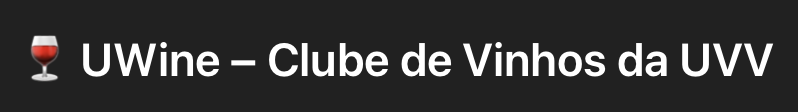

<center>

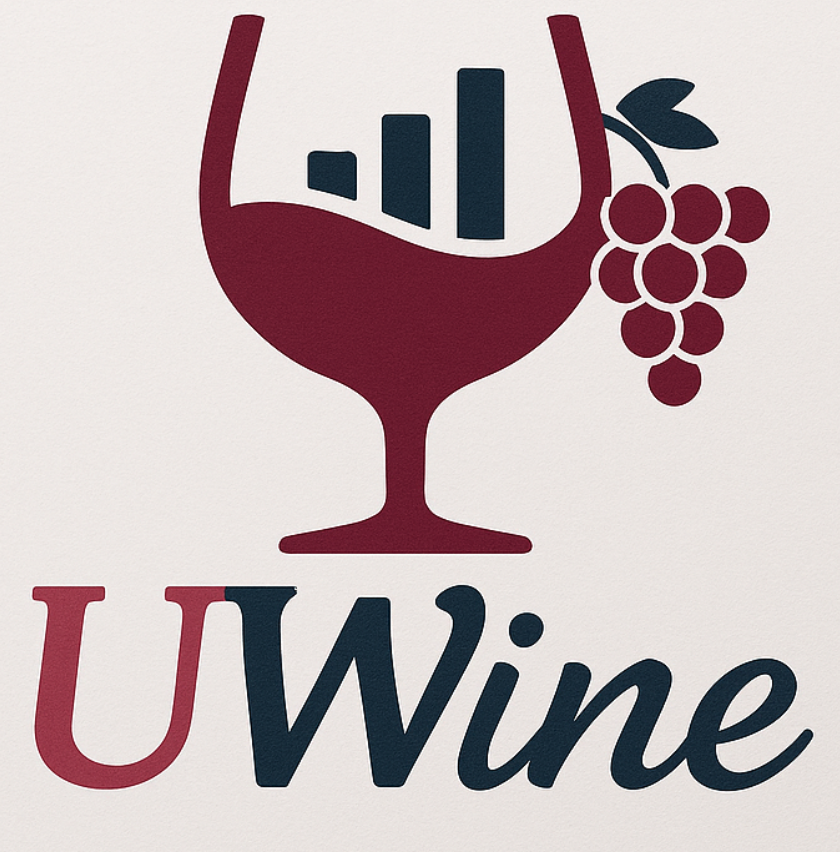

# **Cenário Fictício**:

Prezados(as) alunos(as),

É com entusiasmo que apresento a proposta do **Projeto de Conclusão de Curso (TCC)** para os estudantes do curso de Ciência de Dados da Universidade Vila Velha: o UWine – Clube de Vinhos da UVV.

A proposta do projeto consiste na análise de um Clube de Vinhos universitário fictício, com base em dados simulados, que será totalmente orientado por técnicas e práticas de Ciência de Dados.

Sendo assim, você foi designado como **Consultor em Ciência de Dados** ( ***Data Science Consultant*** ) para fazer uma análise completa dos dados dos clientes a partir de um conjunto de dados (Amostra) com mais de 1 milhão de notas fiscais (~ 350 Megabytes). Além disso, há uma entrada diária de aproximadamente umas 5000 novas notas fiscais no sistema.

O objetivo é permitir que cada consultor(a) percorra foco analíticos diferentes dentro do mesmo ecossistema de dados, aplicando modelos de machine learning supervisionado ou não supervisionado, análise preditiva, dashboards interativos, entre outros.

Para garantir organização, profundidade técnica e coerência metodológica no desenvolvimento do ***Projeto UWine***, adotaremos um workflow composto por cinco etapas principais, alinhadas às boas práticas da Ciência de Dados. Cada etapa representa um marco do processo analítico, permitindo que cada analista avance de forma estruturada do entendimento inicial dos dados até a entrega final dos insights.

# BIBLIOTECAS E FUNÇÕES E CÓDIGOS

In [3]:
import pandas as pd
import numpy as np
import unicodedata
import warnings

import scipy.stats as stats
from scipy.stats import bootstrap
from scipy.stats import anderson, shapiro, normaltest                        # normalidade
from scipy.stats import pearsonr, spearmanr, kendalltau, chi2_contingency    # independência
from scipy.stats import ks_2samp, mannwhitneyu, kruskal, f_oneway, ttest_rel # distribuição
from scipy.stats import ttest_ind, levene                                    # médias

import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50)
sns.set_theme(style='whitegrid')

# ==================================================================
# CONFIGURAÇÕES DO PROJETO
# ==================================================================
SEED = 42                       # semente: todos os sorteios ficam reproduzíveis
ALPHA = 0.05                    # nível de significância dos testes (5%)
TARGET = 'TOTAL (R$)'           # variável-alvo (y)
ESTRATO = 'TIPO DA CONTA'       # variável usada para estratificar
CONTAS = ['ESSENTIAL', 'VIP', 'PRIME']
RESULTADOS = {}                 # guarda os resultados para o RELATÓRIO FINAL

In [4]:
# load do seu TABLE ? aqui: Numero 01
table1 = pd.read_csv('table1 (1).csv', index_col=0)

In [5]:
table1.head()

,NOTA FISCAL,REGIÃO,SEXO,ESTADO CIVIL,DEPENDENTES,RENDA BRUTO (R$),OPINIÃO DO CLIENTE,NOTA DE SATISFAÇÃO (%),MEAN: alcohol,MEAN: malic_acid,MEAN: ash,MEAN: alcalinity_of_ash,MEAN: magnesium,MEAN: total_phenols,MEAN: flavanoids,MEAN: nonflavanoid_phenols,MEAN: proanthocyanins,MEAN: color_intensity,MEAN: hue,MEAN: od280/od315_of_diluted_wines,MEAN: proline,TIPO DA CONTA,TOTAL (R$)
0,5552035,SUDESTE,FEMININO,CASADO,1,3128.66,"Serviço eficiente, recomendo o clube: UVVine",68.68,12.748507,2.966354,2.821273,14.077150,107.561783,2.432549,0.970856,0.339113,1.625648,6.136607,0.599400,2.495998,4.972070,ESSENTIAL,189.71
1,2345034,SUL,MASCULINO,CASADO,1,3277.73,Entrega foi boa e rápida na UVVine,68.68,13.146357,1.748360,2.745618,14.622262,74.391786,3.289910,0.659371,0.316314,1.917911,1.469549,1.085600,2.445723,410.942915,ESSENTIAL,165.88
2,3847978,CENTRO-OESTE,MASCULINO,SOLTEIRO,0,3304.77,Fiquei satisfeito com o serviço da UVVine,68.68,13.129406,1.183999,2.621894,16.462304,102.375411,2.615211,1.578342,0.483084,1.196318,4.210646,0.993294,4.012830,805.329208,ESSENTIAL,332.47
3,8284168,SUDESTE,MASCULINO,CASADO,0,3229.62,Entrega foi boa e rápida na UVVine,68.68,13.346626,1.764604,2.333341,26.161371,114.929009,2.216201,1.178048,0.416199,1.433745,8.059312,0.654584,3.173500,765.172102,ESSENTIAL,163.47
4,3984335,CENTRO-OESTE,MASCULINO,SOLTEIRO,0,3188.87,"Foi aceitável, esperava mais da UVVine",68.68,13.233677,3.267448,2.587921,16.168772,100.269034,1.988131,3.599977,0.028424,1.627156,6.943877,1.040050,2.982482,416.852009,ESSENTIAL,288.99


In [6]:
table1.shape

(1120000, 23)

In [7]:
def optimal_stratified_sample_size(
    df,
    value_column,
    strata_column,
    n_min=100,
    n_max=50000,
    step=100,
    stabilization_threshold=0.01,
    consecutive_points=3,
    plot=True
):
    """
    Estimate the optimal sample size for an infinite stratified population
    using Neyman allocation and consecutive marginal stabilization of the
    stratified standard error.

    Parameters
    ----------
    df : pandas.DataFrame
        Input dataset.

    value_column : str
        Numerical target variable used to estimate the mean.

    strata_column : str
        Categorical stratification variable.

    n_min : int, default=100
        Minimum total sample size evaluated.

    n_max : int, default=50000
        Maximum total sample size evaluated.

    step : int, default=100
        Increment between consecutive sample sizes.

    stabilization_threshold : float, default=0.01
        Maximum relative reduction accepted for standard error stabilization.
        Example: 0.01 means 1%.

    consecutive_points : int, default=3
        Number of consecutive marginal reductions that must remain below
        the stabilization threshold.

    plot : bool, default=True
        If True, plot the standard error stabilization curve.

    Returns
    -------
    summary : pandas.DataFrame
        Sample allocation per stratum.

    results : dict
        Dictionary containing:
        - optimal_n
        - optimal_standard_error
        - sample_sizes
        - standard_error_curve
        - marginal_reduction
        - stabilization_threshold
        - consecutive_points
        - strata_statistics
    """

    # Keep only the required columns and remove missing values
    data = df[[value_column, strata_column]].dropna().copy()

    # Convert the target variable to numeric
    data[value_column] = pd.to_numeric(data[value_column], errors="coerce")
    data = data.dropna()

    if data.empty:
        raise ValueError("The dataset is empty after removing missing or invalid values.")

    # Estimate stratum weights
    weights = (
        data[strata_column]
        .value_counts(normalize=True)
        .sort_index()
    )

    # Estimate stratum standard deviations
    stds = (
        data.groupby(strata_column)[value_column]
        .std()
        .sort_index()
    )

    # Align both series
    stds = stds.loc[weights.index]

    strata = weights.index.values
    Wh = weights.values
    Sh = stds.values

    if np.any(np.isnan(Sh)):
        raise ValueError(
            "At least one stratum has insufficient observations "
            "to calculate standard deviation."
        )

    if np.any(Sh == 0):
        print(
            "Warning: At least one stratum has zero standard deviation. "
            "Neyman allocation may assign a very small sample to this stratum."
        )

    # Neyman allocation weights
    neyman_weights = Wh * Sh

    if neyman_weights.sum() == 0:
        raise ValueError(
            "Neyman weights are zero. Check the variability of the target variable."
        )

    sample_sizes = np.arange(n_min, n_max + step, step)

    standard_errors = []
    allocations = []

    for n in sample_sizes:

        nh = n * neyman_weights / neyman_weights.sum()

        se = np.sqrt(
            np.sum(
                (Wh ** 2) * (Sh ** 2) / nh
            )
        )

        standard_errors.append(se)
        allocations.append(nh)

    standard_errors = np.array(standard_errors)
    allocations = np.array(allocations)

    # Marginal relative reduction of the standard error
    marginal_reduction = (
        np.abs(np.diff(standard_errors)) / standard_errors[:-1]
    )

    stable_sequence_index = None

    for i in range(0, len(marginal_reduction) - consecutive_points + 1):

        window = marginal_reduction[i:i + consecutive_points]

        if np.all(window < stabilization_threshold):
            stable_sequence_index = i
            break

    if stable_sequence_index is None:
        raise ValueError(
            "No consecutive stabilization point found within the evaluated interval. "
            "Try increasing n_max, increasing step, or using a larger threshold."
        )

    optimal_index = stable_sequence_index + consecutive_points

    optimal_n = sample_sizes[optimal_index]
    optimal_se = standard_errors[optimal_index]
    optimal_allocation = allocations[optimal_index]

    summary = pd.DataFrame({
        "Stratum": strata,
        "Population Weight (Wh)": Wh,
        "Std. Deviation (Sh)": Sh,
        "Neyman Weight (Wh x Sh)": neyman_weights,
        "Allocated Sample (nh)": np.round(optimal_allocation).astype(int)
    })

    summary["Allocated Sample (%)"] = (
        summary["Allocated Sample (nh)"] /
        summary["Allocated Sample (nh)"].sum()
    )

    strata_statistics = pd.DataFrame({
        "Stratum": strata,
        "Wh": Wh,
        "Sh": Sh,
        "Wh_x_Sh": neyman_weights
    })

    if plot:

        plt.figure(figsize=(11, 6))

        plt.plot(
            sample_sizes,
            standard_errors,
            linewidth=3,
            label="Stratified standard error"
        )

        plt.scatter(
            optimal_n,
            optimal_se,
            s=120,
            label="Optimal sample size"
        )

        plt.axvline(
            optimal_n,
            linestyle="--"
        )

        plt.text(
            optimal_n,
            optimal_se,
            f"  n = {optimal_n}\n  SE = {optimal_se:.4f}",
            verticalalignment="bottom"
        )

        plt.xlabel("Total Sample Size (n)")
        plt.ylabel("Stratified Standard Error")
        plt.title("Consecutive Marginal Stabilization of the Standard Error")
        plt.grid(True)
        plt.legend()
        plt.show()

    results = {
        "optimal_n": int(optimal_n),
        "optimal_standard_error": float(optimal_se),
        "sample_sizes": sample_sizes,
        "standard_error_curve": standard_errors,
        "marginal_reduction": marginal_reduction,
        "stabilization_threshold": stabilization_threshold,
        "consecutive_points": consecutive_points,
        "strata_statistics": strata_statistics
    }

    return summary, results

In [8]:
def optimal_sample_size(df, value_column, n_min=100, n_max=50000, step=100,
                        stabilization_threshold=0.01, consecutive_points=3, plot=True):
    """
    Procedimento EMPÍRICO (material "Tamanho Ideal da Amostra"):
    estabilização marginal consecutiva do erro-padrão.

    Calcula EP(n) = s / sqrt(n) para n = n_min, n_min + step, ..., n_max.
    A estabilização acontece quando a redução do erro-padrão a cada
    novo incremento (ΔEP) fica <= stabilization_threshold durante
    consecutive_points incrementos seguidos.

    Parameters
    ----------
    df : pandas.DataFrame
        Dados de referência.
    value_column : str
        Variável numérica analisada (ex.: 'TOTAL (R$)').
    n_min, n_max, step : int
        Intervalo de tamanhos de amostra avaliados.
    stabilization_threshold : float
        Redução marginal máxima aceita (ex.: 0.001 = R$ 0,001).
    consecutive_points : int
        Quantidade de incrementos consecutivos exigidos.
    plot : bool
        Se True, mostra a curva do erro-padrão com janela de zoom.

    Returns
    -------
    dict
        optimal_sample_size, standard_error, mean_standard_error,
        population_standard_deviation, stabilization_found, results.
    """
    values = pd.to_numeric(df[value_column], errors="coerce").dropna()
    s = float(values.std(ddof=1))

    sample_sizes = np.arange(n_min, n_max + 1, step, dtype=int)
    standard_errors = s / np.sqrt(sample_sizes)
    mean_standard_error = float(np.mean(standard_errors))

    marginal = np.full(len(standard_errors), np.nan)
    marginal[1:] = standard_errors[:-1] - standard_errors[1:]
    stable = np.zeros(len(sample_sizes), dtype=bool)
    stable[1:] = marginal[1:] <= stabilization_threshold

    # Procura a primeira sequência de 'consecutive_points' pontos estáveis
    confirmation, count = None, 0
    for i in range(1, len(sample_sizes)):
        count = count + 1 if stable[i] else 0
        if count >= consecutive_points:
            confirmation = i
            break

    found = confirmation is not None
    optimal_n = int(sample_sizes[confirmation]) if found else None
    optimal_se = float(standard_errors[confirmation]) if found else None

    if plot:
        fig, ax = plt.subplots(figsize=(15, 7), layout="constrained")
        ax.plot(sample_sizes, standard_errors, color="#2878B5", linewidth=2.6)
        ax.axhline(mean_standard_error, color="#D62728", linestyle="--", linewidth=2)
        ax.text(n_max, mean_standard_error, f" Erro-padrão médio = {mean_standard_error:.4f}",
                color="#D62728", va="bottom", ha="right")
        if found:
            start = confirmation - consecutive_points + 1
            idx = np.arange(start, confirmation + 1)
            ax.scatter(sample_sizes[idx], standard_errors[idx], s=90, color="#FF9F1C", zorder=5)
            ax.scatter(optimal_n, optimal_se, s=180, color="#D62728", zorder=6)
            ax.axvline(optimal_n, color="#D62728", linestyle=":")
            ax.annotate(f"n recomendado = {optimal_n:,}\nEP = {optimal_se:.4f}".replace(",", "."),
                        xy=(optimal_n, optimal_se), xytext=(25, 40), textcoords="offset points",
                        bbox={"boxstyle": "round", "fc": "white", "ec": "#D62728"},
                        arrowprops={"arrowstyle": "->", "color": "#D62728"})
            # Janela de zoom nos pontos consecutivos
            ins = inset_axes(ax, width="40%", height="40%", loc="upper right", borderpad=1.8)
            ctx = np.arange(max(start - 1, 0), min(confirmation + 1, len(sample_sizes) - 1) + 1)
            ins.plot(sample_sizes[ctx], standard_errors[ctx], marker="o", color="#2878B5")
            ins.scatter(sample_sizes[idx], standard_errors[idx], s=70, color="#FF9F1C", zorder=5)
            ins.scatter(optimal_n, optimal_se, s=110, color="#D62728", zorder=6)
            ins.set_title(f"Janela ampliada: {consecutive_points} pontos consecutivos", fontsize=10)
            ins.tick_params(labelsize=8)
            mark_inset(ax, ins, loc1=2, loc2=4, fc="none", ec="#E76F8A")
            titulo = f"Estabilização confirmada em n = {optimal_n:,}".replace(",", ".")
        else:
            titulo = "Estabilização não encontrada no intervalo analisado"
        ax.set_title("Estabilização Marginal Consecutiva do Erro-Padrão\n" + titulo,
                     fontsize=14, fontweight="bold")
        ax.set_xlabel("Tamanho da amostra (n)")
        ax.set_ylabel("Erro-padrão")
        plt.show()
        return {"optimal_sample_size": optimal_n, "standard_error": optimal_se,
            "mean_standard_error": mean_standard_error,
            "population_standard_deviation": s, "stabilization_found": found}

In [9]:
def bootstrap_distribution_eda(data, metric=np.mean, bins=30, confidence_level=0.90,
                               titulo=None, xlabel='Statistic Value',
                               valor_referencia=None, rotulo_referencia='Referência'):
    """
    Função de apoio (material da disciplina): distribuição BOOTSTRAP de
    uma estatística, com intervalo de confiança e erro-padrão.

    Adaptação: method='percentile' e batch=250, para rodar com amostras
    grandes sem estourar a memória do Colab; titulo e valor_referencia
    deixam o gráfico autoexplicativo.

    Parameters
    ----------
    data : array-like
        Amostra (uma dimensão).
    metric : callable
        Estatística aplicada a cada reamostragem (ex.: np.mean).
    bins : int
        Número de barras do histograma.
    confidence_level : float
        Nível de confiança do intervalo (ex.: 0.95).
    titulo, xlabel : str
        Título e eixo x do gráfico.
    valor_referencia : float, optional
        Linha de referência (ex.: média real da população).

    Returns
    -------
    BootstrapResult
        Distribuição bootstrap, intervalo de confiança e erro-padrão.
    """
    res = bootstrap((np.asarray(data),), metric, confidence_level=confidence_level,
                    n_resamples=2000, method='percentile', batch=250,
                    random_state=np.random.default_rng(SEED))
    dist = res.bootstrap_distribution

    plt.figure(figsize=(10, 5))
    sns.histplot(dist, bins=bins, kde=True, stat="density", color='steelblue')
    plt.axvline(np.mean(dist), color='black', label=f'Média bootstrap = {np.mean(dist):.4f}')
    plt.axvline(res.confidence_interval.low, color='red', linestyle='--',
                label=f'IC inferior = {res.confidence_interval.low:.4f}')
    plt.axvline(res.confidence_interval.high, color='red', linestyle='--',
                label=f'IC superior = {res.confidence_interval.high:.4f}')
    if valor_referencia is not None:
        plt.axvline(valor_referencia, color='green', linestyle=':', linewidth=2.5,
                    label=f'{rotulo_referencia} = {valor_referencia:.4f}')
    plt.title(titulo or "Bootstrap Sampling Distribution", fontweight='bold')
    plt.xlabel(xlabel)
    plt.ylabel("Densidade")
    plt.legend()
    plt.show()

    print(f"INTERVALO DE CONFIANÇA ({confidence_level:.0%}): "
          f"[{res.confidence_interval.low:.4f} ; {res.confidence_interval.high:.4f}]")
    print(f"ERRO-PADRÃO BOOTSTRAP: {res.standard_error:.4f}")
    return res

In [10]:
def bootstrap_diferenca(x, y, func=np.mean, n_boot=2000, lote=200):
    """
    Bootstrap da DIFERENÇA de uma estatística entre duas amostras
    independentes: func(reamostra de x) - func(reamostra de y).
    Se o intervalo de 95% contém o ZERO, não há diferença entre elas.

    Returns
    -------
    numpy.ndarray
        Distribuição bootstrap da diferença.
    """
    rng = np.random.default_rng(SEED)
    x, y = np.asarray(x), np.asarray(y)
    difs = np.empty(n_boot)
    for i in range(0, n_boot, lote):
        k = min(lote, n_boot - i)
        bx = func(x[rng.integers(0, len(x), size=(k, len(x)))], axis=1)
        by = func(y[rng.integers(0, len(y), size=(k, len(y)))], axis=1)
        difs[i:i + k] = bx - by
    return difs

def grafico_bootstrap(dist, titulo, xlabel, referencia=0.0, rotulo='Sem diferença (0)'):
    """
    Gráfico da distribuição bootstrap: histograma + IC 95% (vermelho)
    + linha de referência (verde). Retorna (IC inferior, IC superior).
    """
    low, high = np.percentile(dist, [2.5, 97.5])
    plt.figure(figsize=(10, 5))
    sns.histplot(dist, bins=40, kde=True, stat='density', color='steelblue')
    plt.axvline(low, color='red', linestyle='--', label=f'IC 95% inferior = {low:.4f}')
    plt.axvline(high, color='red', linestyle='--', label=f'IC 95% superior = {high:.4f}')
    plt.axvline(referencia, color='green', linestyle=':', linewidth=2.5,
                label=f'{rotulo} = {referencia}')
    plt.title(titulo, fontweight='bold')
    plt.xlabel(xlabel)
    plt.ylabel('Densidade')
    plt.legend()
    plt.show()
    return low, high


def grafico_pvalores(tabela, titulo, best_fit):
    """
    Barras com o p_value de cada teste e a linha de significância
    α = 0,05. O BEST FIT aparece em destaque (vinho).
    """
    cores = ['#7B2D3B' if t == best_fit else '#9DB4C0' for t in tabela.index]
    plt.figure(figsize=(11, 4.5))
    barras = plt.bar(tabela.index, tabela['p_value'], color=cores)
    plt.axhline(ALPHA, color='red', linestyle='--', label='α = 0,05')
    for b, p in zip(barras, tabela['p_value']):
        plt.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.02, f'{p:.4f}', ha='center')
    plt.ylim(0, 1.1)
    plt.ylabel('p_value')
    plt.title(f'{titulo}\nBEST FIT em destaque: {best_fit}', fontweight='bold')
    plt.legend()
    plt.show()

# Workflow: Detalhamento das Atividades

##Atividade A1: Estratificação amostral da população

###Atividade A1.1: Determinar o TAMANHO IDEAL da amostra

Criar os (4) gráficos do ERRO-PADRÃO-MÉDIO (TARGET: $y$: **TOTAL (R$)**) das seguintes categorias:

*   **ESSENTIAL**
*   **VIP**
*   **PRIME**
*   **GERAL**

Fazer a **ANÁLISE BOOTSTRAP** para determinar:
*   **Intervalo de confiança**.
*   **Erro padrão**.
*   **RESPONDER: Qual é o "Tamanho Ideal" da amostra ?**

Determinação do Tamanho Ideal da Amostra em Populações Infinitas Estratificadas: [Link](https://drive.google.com/file/d/1aLWDSNRrjr03ItMSE_3joXYmdoC09jQm/view?usp=sharing)

Usar a Função - Determinação do Tamanho Ideal da Amostra em Populações Infinitas Estratificadas, por dois(2) procedimentos a saber:

*   Procedimento empírico: Estabilização marginal do erro-padrão: **optimal_sample_size**
*   Procedimento teórico-empírico: Estabilização marginal do erro-padrão estratificado e otimização de Neyman: **optimal_stratified_sample_size**



In [11]:
# exemplo de como exibir Relatório: Fazer todos modularizados

 1. ERRO-PADRÃO MÉDIO — ESSENTIAL, VIP, PRIME e GERAL (procedimento empírico)

>>> ESSENTIAL: 716.565 notas fiscais


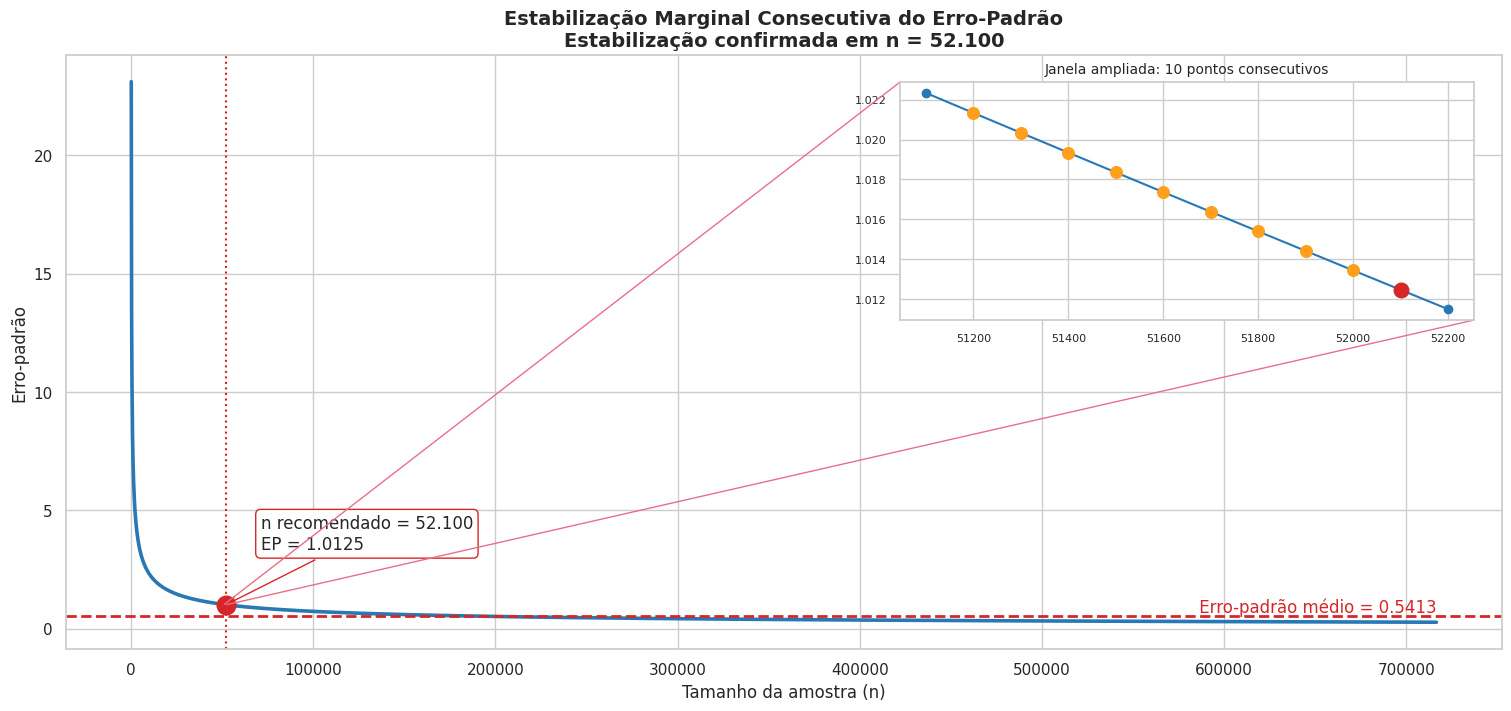


>>> VIP: 236.774 notas fiscais


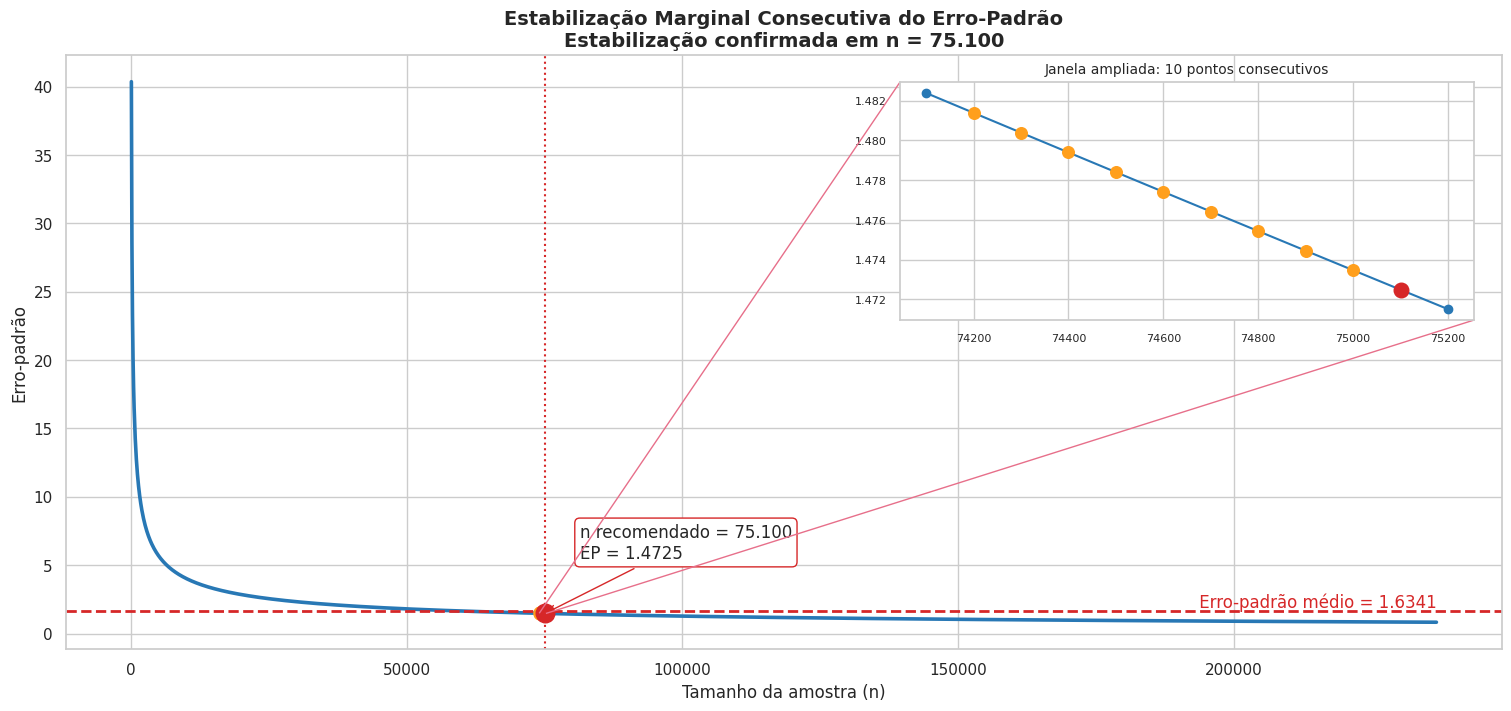


>>> PRIME: 166.661 notas fiscais


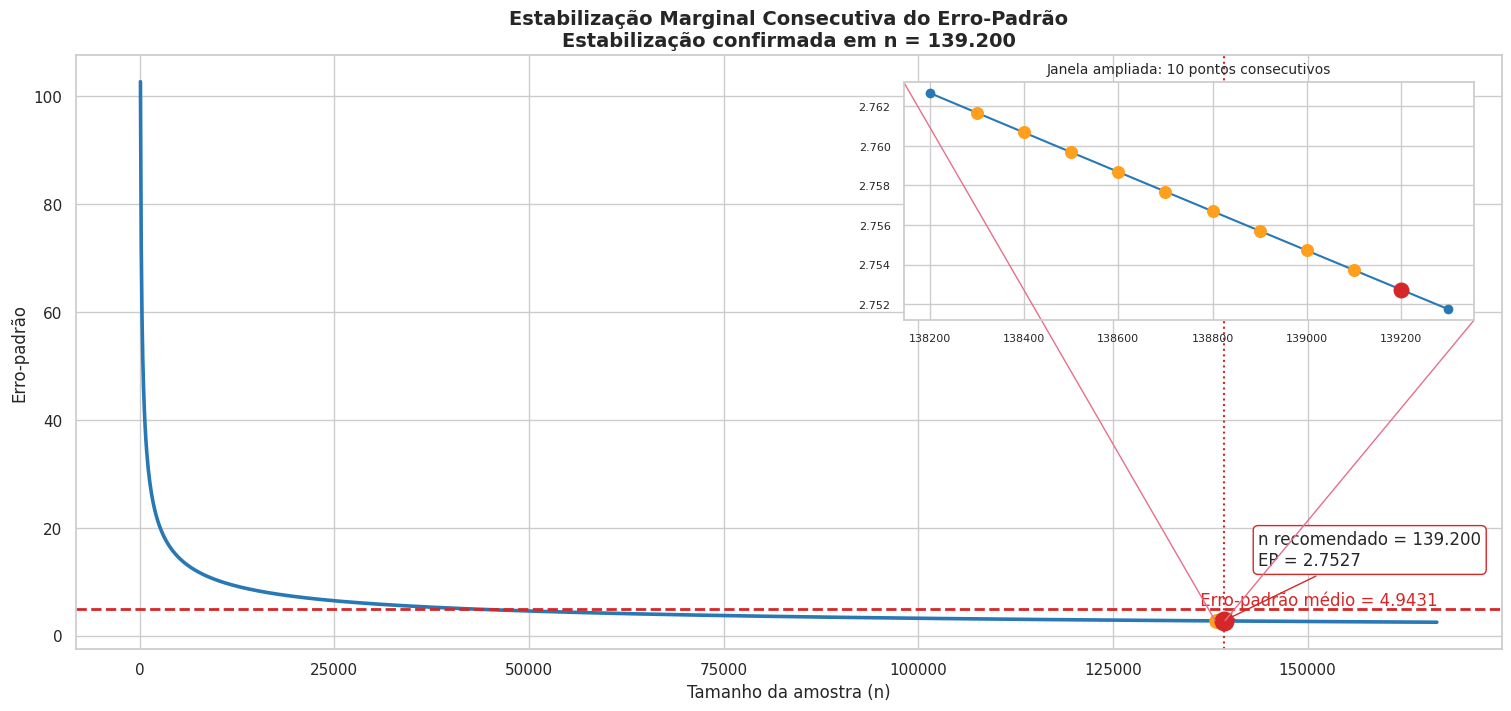


>>> GERAL: 1.120.000 notas fiscais


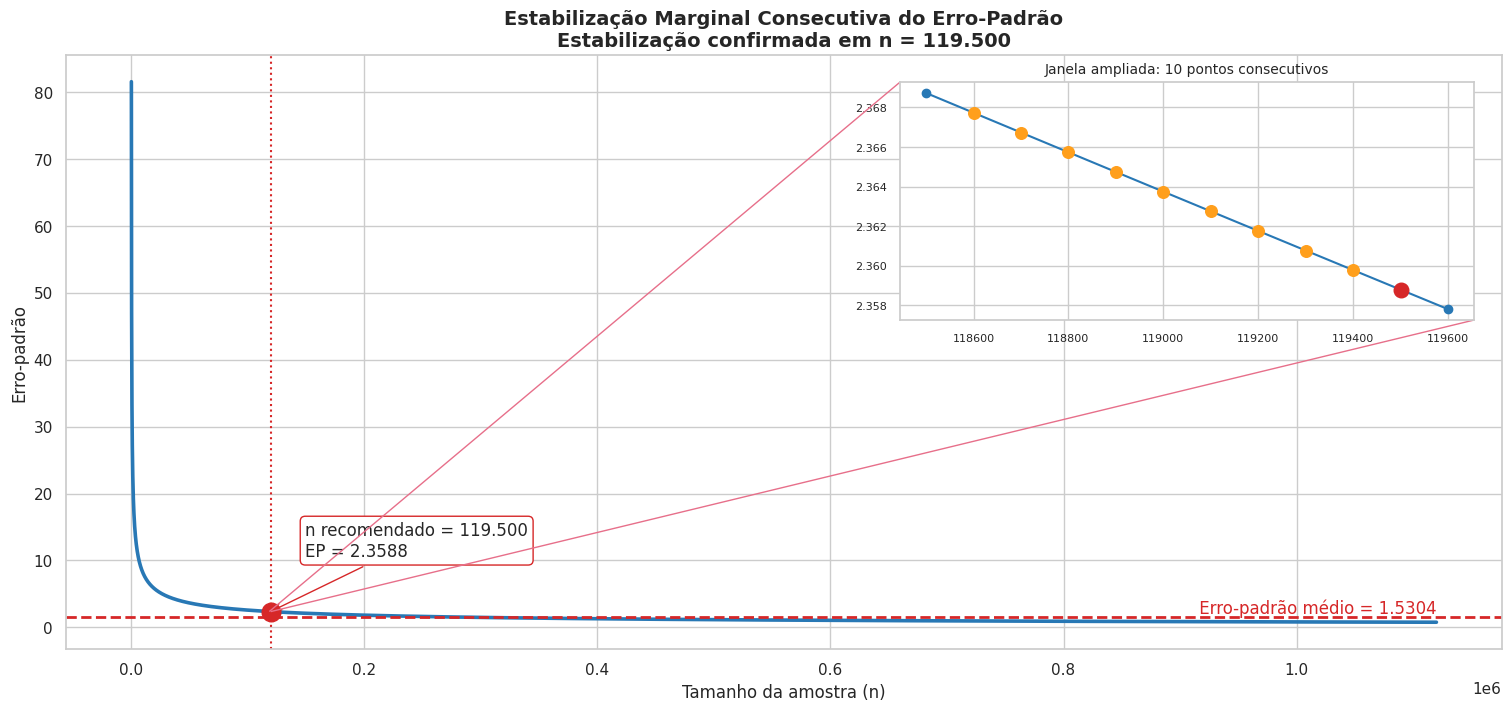

,Desvio-padrão (R$),n recomendado,Erro-padrão no n (R$),Erro-padrão médio (R$)
Grupo,,,,
ESSENTIAL,231.1012,52100,1.0125,0.5413
VIP,403.5251,75100,1.4725,1.6341
PRIME,1027.0306,139200,2.7527,4.9431
GERAL,815.4061,119500,2.3588,1.5304



 2. TAMANHO IDEAL — erro-padrão estratificado + otimização de Neyman


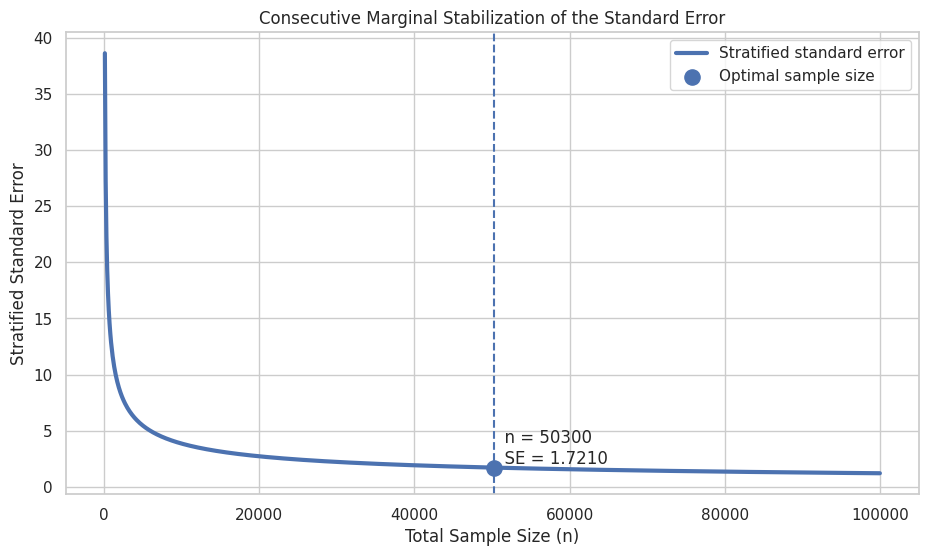

,Population Weight (Wh),Std. Deviation (Sh),Neyman Weight (Wh x Sh),Allocated Sample (nh),Allocated Sample (%)
Stratum,,,,,
ESSENTIAL,0.6398,231.1012,147.8563,19268,0.3831
VIP,0.2114,403.5251,85.3074,11117,0.2210
PRIME,0.1488,1027.0306,152.8267,19915,0.3959



 3. ANÁLISE BOOTSTRAP — amostra estratificada de n = 50.300

>>> ESSENTIAL (n = 19.268)


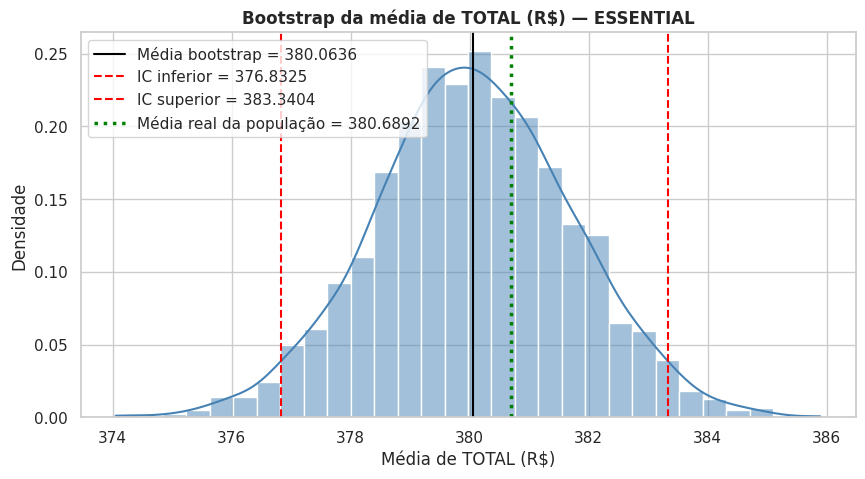

INTERVALO DE CONFIANÇA (95%): [376.8325 ; 383.3404]
ERRO-PADRÃO BOOTSTRAP: 1.6568

>>> VIP (n = 11.117)


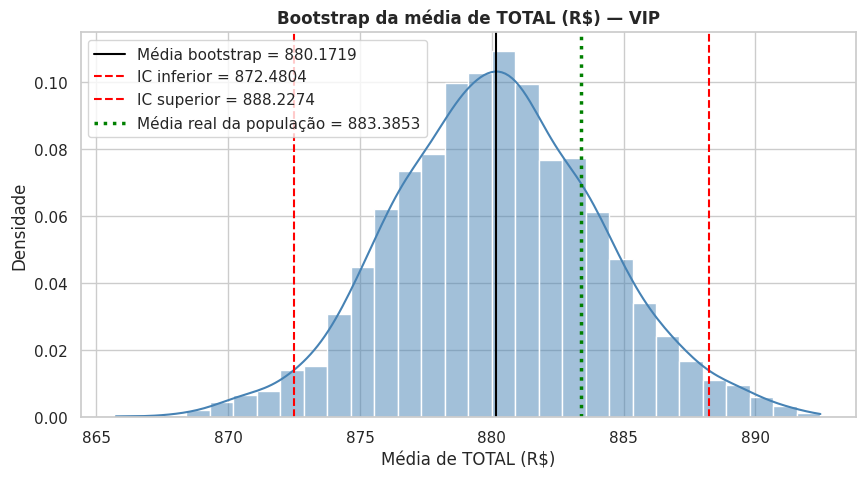

INTERVALO DE CONFIANÇA (95%): [872.4804 ; 888.2274]
ERRO-PADRÃO BOOTSTRAP: 3.9479

>>> PRIME (n = 19.915)


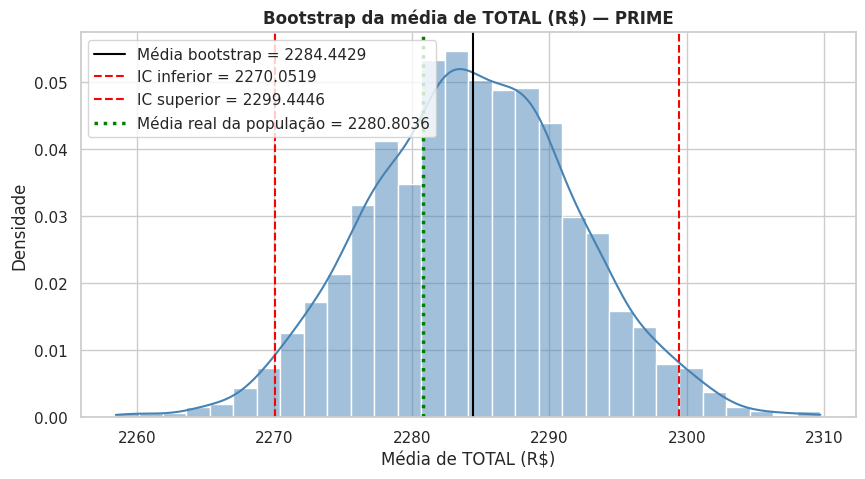

INTERVALO DE CONFIANÇA (95%): [2270.0519 ; 2299.4446]
ERRO-PADRÃO BOOTSTRAP: 7.4804

>>> GERAL (n = 50.300)


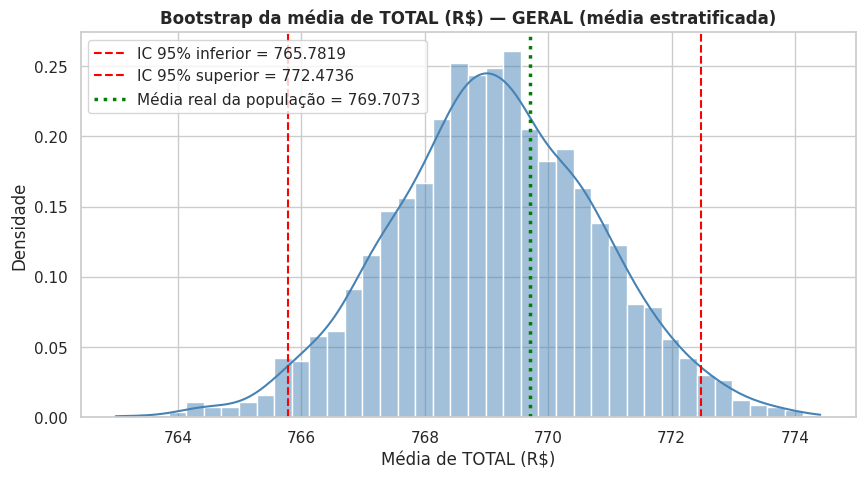

,n,Média da amostra,Média real,Erro-padrão,IC 95% inferior,IC 95% superior,Média real dentro do IC?
Grupo,,,,,,,
ESSENTIAL,19268,380.0295,380.6892,1.6568,376.8325,383.3404,Sim
VIP,11117,880.1212,883.3853,3.9479,872.4804,888.2274,Sim
PRIME,19915,2284.4756,2280.8036,7.4804,2270.0519,2299.4446,Sim
GERAL,50300,769.1417,769.7073,1.6845,765.7819,772.4736,Sim



 4. RESPOSTA: o TAMANHO IDEAL da amostra é n = 50.300 notas fiscais
    ESSENTIAL : 19.268 notas fiscais
    VIP       : 11.117 notas fiscais
    PRIME     : 19.915 notas fiscais
    Erro-padrão estratificado: R$ 1.7210


In [12]:
def AtividadeA1_1(df):
    """
    ATIVIDADE A1.1 — Determinar o TAMANHO IDEAL da amostra.

    Etapas (na ordem pedida no Workflow):
    1. Gráficos do ERRO-PADRÃO MÉDIO do TOTAL (R$) para ESSENTIAL, VIP,
       PRIME e GERAL -> procedimento empírico (optimal_sample_size).
    2. Procedimento teórico-empírico: erro-padrão estratificado +
       otimização de Neyman (optimal_stratified_sample_size).
    3. ANÁLISE BOOTSTRAP numa amostra estratificada de tamanho ideal:
       intervalo de confiança (95%) e erro-padrão.
    4. RESPOSTA: qual é o tamanho ideal da amostra.

    Parameters
    ----------
    df : pandas.DataFrame
        Base de dados completa (table1).

    Returns
    -------
    dict
        n_ideal e alocacao (tamanho da amostra de cada TIPO DA CONTA).
    """
    # --------------------------------------------------------------
    # 1. GRÁFICOS DO ERRO-PADRÃO MÉDIO (procedimento empírico)
    # --------------------------------------------------------------
    print('=' * 72)
    print(' 1. ERRO-PADRÃO MÉDIO — ESSENTIAL, VIP, PRIME e GERAL (procedimento empírico)')
    print('=' * 72)
    linhas = []
    for grupo in CONTAS + ['GERAL']:
        dados = df if grupo == 'GERAL' else df[df[ESTRATO] == grupo]
        print(f'\n>>> {grupo}: {len(dados):,} notas fiscais'.replace(',', '.'))
        r = optimal_sample_size(dados, TARGET, n_min=100, n_max=len(dados), step=100,
                                stabilization_threshold=0.001, consecutive_points=10)
        linhas.append({'Grupo': grupo,
                       'Desvio-padrão (R$)': r['population_standard_deviation'],
                       'n recomendado': r['optimal_sample_size'],
                       'Erro-padrão no n (R$)': r['standard_error'],
                       'Erro-padrão médio (R$)': r['mean_standard_error']})
    display(pd.DataFrame(linhas).set_index('Grupo').round(4))

    # --------------------------------------------------------------
    # 2. PROCEDIMENTO TEÓRICO-EMPÍRICO (Neyman)
    # --------------------------------------------------------------
    print('\n' + '=' * 72)
    print(' 2. TAMANHO IDEAL — erro-padrão estratificado + otimização de Neyman')
    print('=' * 72)
    summary, res = optimal_stratified_sample_size(
        df, TARGET, ESTRATO, n_min=100, n_max=100_000, step=100,
        stabilization_threshold=0.001, consecutive_points=3)
    summary = summary.set_index('Stratum').loc[CONTAS]
    n_ideal = res['optimal_n']
    alocacao = {c: int(v) for c, v in summary['Allocated Sample (nh)'].items()}
    alocacao['ESSENTIAL'] += n_ideal - sum(alocacao.values())   # ajuste do arredondamento
    summary['Allocated Sample (nh)'] = pd.Series(alocacao)
    display(summary.round(4))

    # --------------------------------------------------------------
    # 3. ANÁLISE BOOTSTRAP (intervalo de confiança e erro-padrão)
    # --------------------------------------------------------------
    print('\n' + '=' * 72)
    print(f' 3. ANÁLISE BOOTSTRAP — amostra estratificada de n = {n_ideal:,}'.replace(',', '.'))
    print('=' * 72)
    amostra = pd.concat([df[df[ESTRATO] == c].sample(n=alocacao[c], random_state=SEED)
                         for c in CONTAS])
    linhas = []
    for c in CONTAS:
        x = amostra.loc[amostra[ESTRATO] == c, TARGET].to_numpy()
        media_real = df.loc[df[ESTRATO] == c, TARGET].mean()
        print(f'\n>>> {c} (n = {len(x):,})'.replace(',', '.'))
        b = bootstrap_distribution_eda(
            x, np.mean, confidence_level=0.95,
            titulo=f'Bootstrap da média de TOTAL (R$) — {c}', xlabel='Média de TOTAL (R$)',
            valor_referencia=media_real, rotulo_referencia='Média real da população')
        linhas.append({'Grupo': c, 'n': len(x), 'Média da amostra': x.mean(),
                       'Média real': media_real, 'Erro-padrão': b.standard_error,
                       'IC 95% inferior': b.confidence_interval.low,
                       'IC 95% superior': b.confidence_interval.high})

    # GERAL: média ESTRATIFICADA = soma(peso do estrato x média do estrato)
    pesos = df[ESTRATO].value_counts(normalize=True)
    rng = np.random.default_rng(SEED)
    dist_geral = np.zeros(2000)
    for c in CONTAS:
        x = amostra.loc[amostra[ESTRATO] == c, TARGET].to_numpy()
        dist_geral += pesos[c] * np.array([rng.choice(x, len(x)).mean() for _ in range(2000)])
    media_real = df[TARGET].mean()
    print(f'\n>>> GERAL (n = {n_ideal:,})'.replace(',', '.'))
    low, high = grafico_bootstrap(dist_geral, 'Bootstrap da média de TOTAL (R$) — GERAL '
                                  '(média estratificada)', 'Média de TOTAL (R$)',
                                  referencia=round(media_real, 4), rotulo='Média real da população')
    linhas.append({'Grupo': 'GERAL', 'n': n_ideal,
                   'Média da amostra': sum(pesos[c] * amostra.loc[amostra[ESTRATO] == c, TARGET]
                                           .mean() for c in CONTAS),
                   'Média real': media_real, 'Erro-padrão': dist_geral.std(ddof=1),
                   'IC 95% inferior': low, 'IC 95% superior': high})
    tabela = pd.DataFrame(linhas).set_index('Grupo')
    tabela['Média real dentro do IC?'] = np.where(
        tabela['Média real'].between(tabela['IC 95% inferior'], tabela['IC 95% superior']),
        'Sim', 'Não')
    display(tabela.round(4))

    # --------------------------------------------------------------
    # 4. RESPOSTA
    # --------------------------------------------------------------
    print('\n' + '=' * 72)
    print(f' 4. RESPOSTA: o TAMANHO IDEAL da amostra é n = {n_ideal:,} notas fiscais'
          .replace(',', '.'))
    print('=' * 72)
    for c in CONTAS:
        print(f'    {c:<10}: {alocacao[c]:>6,} notas fiscais'.replace(',', '.'))
    print(f'    Erro-padrão estratificado: R$ {res["optimal_standard_error"]:.4f}')

    RESULTADOS.update({'n_ideal': n_ideal, 'alocacao': alocacao,
                       'ep_estratificado': res['optimal_standard_error'],
                       'bootstrap_a11': tabela})
    return {'n_ideal': n_ideal, 'alocacao': alocacao}


resultado_A1_1 = AtividadeA1_1(table1)

###Atividade A1.2: Analisar os outliers

1. BOXPLOT


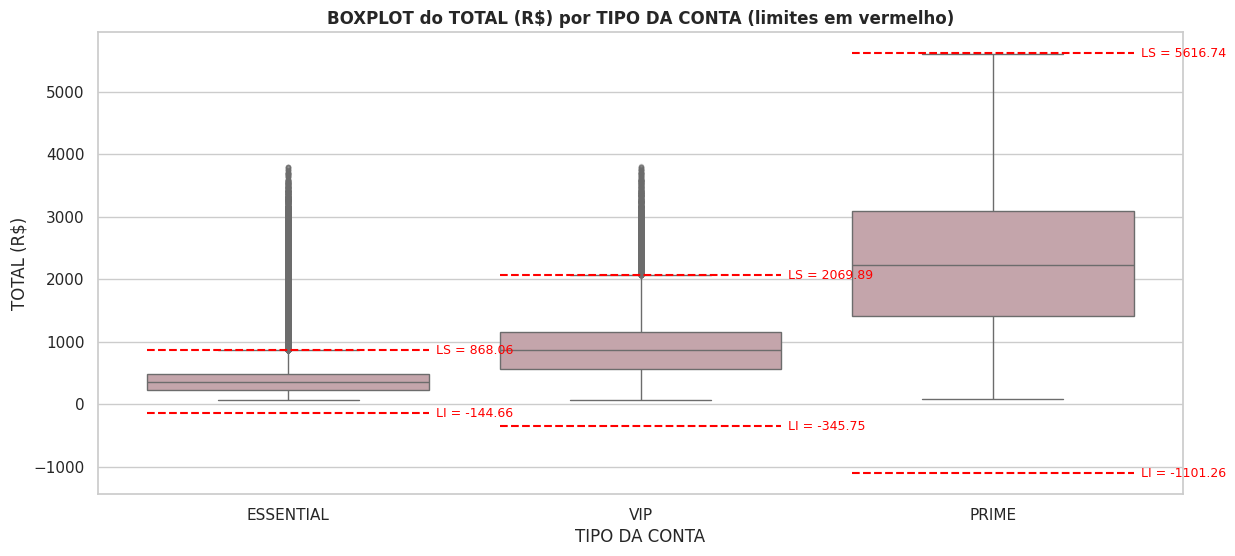

2. LIMITES INFERIOR E SUPERIOR  |  3. ACIMA DO LIMITE SUPERIOR  |  4. ABAIXO DO LIMITE INFERIOR


,Q1,Q3,IQR,Limite inferior,Limite superior,Acima do limite superior,Abaixo do limite inferior
TIPO DA CONTA,,,,,,,
ESSENTIAL,235.11,488.29,253.18,-144.66,868.06,9872,0
VIP,560.12,1164.03,603.91,-345.74,2069.90,2910,0
PRIME,1417.99,3097.49,1679.50,-1101.26,5616.74,0,0



5. DROPAR OS OUTLIERS?
   Outliers encontrados: 12.782 (1.14% da base)
   Base original: 1.120.000  |  Base sem outliers: 1.107.218
   RESPOSTA: SIM. São poucos registros, fora do padrão de gasto do próprio tipo
   de conta, e eles aumentam o desvio-padrão (que define o tamanho da amostra).


,Média COM outliers,Média SEM outliers,Desvio COM outliers,Desvio SEM outliers
TIPO DA CONTA,,,,
ESSENTIAL,380.69,361.28,231.10,142.33
VIP,883.39,861.46,403.53,351.41
PRIME,2280.80,2280.80,1027.03,1027.03


In [13]:
def AtividadeA1_2(df):
    """
    ATIVIDADE A1.2 — Analisar os outliers do TOTAL (R$).

    Regra do boxplot (IQR), calculada dentro de cada TIPO DA CONTA:
        IQR = Q3 - Q1
        Limite inferior = Q1 - 1,5 x IQR
        Limite superior = Q3 + 1,5 x IQR

    Etapas:
    1. Boxplot por TIPO DA CONTA.
    2. Limites inferior e superior.
    3. Quantidade de amostras acima do limite superior.
    4. Quantidade de amostras abaixo do limite inferior.
    5. Dropar os outliers? -> retorna a base sem outliers.

    Parameters
    ----------
    df : pandas.DataFrame
        Base de dados completa (table1).

    Returns
    -------
    pandas.DataFrame
        Base sem outliers (table_limpo).
    """
    linhas = []
    outlier = pd.Series(False, index=df.index)
    for c in CONTAS:
        x = df.loc[df[ESTRATO] == c, TARGET]
        q1, q3 = x.quantile(0.25), x.quantile(0.75)
        iqr = q3 - q1
        li, ls = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        outlier.loc[x.index] = (x > ls) | (x < li)
        linhas.append({'TIPO DA CONTA': c, 'Q1': q1, 'Q3': q3, 'IQR': iqr,
                       'Limite inferior': li, 'Limite superior': ls,
                       'Acima do limite superior': int((x > ls).sum()),
                       'Abaixo do limite inferior': int((x < li).sum())})
    tabela = pd.DataFrame(linhas).set_index('TIPO DA CONTA')

    # 1. BOXPLOT
    print('1. BOXPLOT')
    fig, ax = plt.subplots(figsize=(14, 6))
    sns.boxplot(data=df, x=ESTRATO, y=TARGET, order=CONTAS, color='#C9A0A8', ax=ax,
                flierprops={'marker': '.', 'alpha': 0.3})
    for i, c in enumerate(CONTAS):
        li, ls = tabela.loc[c, 'Limite inferior'], tabela.loc[c, 'Limite superior']
        ax.hlines([li, ls], i - 0.4, i + 0.4, colors='red', linestyles='--')
        ax.text(i + 0.42, ls, f'LS = {ls:.2f}', color='red', fontsize=9, va='center')
        ax.text(i + 0.42, li, f'LI = {li:.2f}', color='red', fontsize=9, va='center')
    ax.set_title('BOXPLOT do TOTAL (R$) por TIPO DA CONTA (limites em vermelho)',
                 fontweight='bold')
    plt.show()

    # 2, 3 e 4. LIMITES E QUANTIDADES
    print('2. LIMITES INFERIOR E SUPERIOR  |  3. ACIMA DO LIMITE SUPERIOR  |  '
          '4. ABAIXO DO LIMITE INFERIOR')
    display(tabela.round(2))

    # 5. DROPAR OS OUTLIERS?
    df_limpo = df[~outlier].copy()
    total = int(outlier.sum())
    print('\n5. DROPAR OS OUTLIERS?')
    print(f'   Outliers encontrados: {total:,} ({total / len(df):.2%} da base)'.replace(',', '.'))
    print(f'   Base original: {len(df):,}  |  Base sem outliers: {len(df_limpo):,}'
          .replace(',', '.'))
    print('   RESPOSTA: SIM. São poucos registros, fora do padrão de gasto do próprio tipo')
    print('   de conta, e eles aumentam o desvio-padrão (que define o tamanho da amostra).')
    comparacao = pd.DataFrame({
        'Média COM outliers': df.groupby(ESTRATO)[TARGET].mean(),
        'Média SEM outliers': df_limpo.groupby(ESTRATO)[TARGET].mean(),
        'Desvio COM outliers': df.groupby(ESTRATO)[TARGET].std(),
        'Desvio SEM outliers': df_limpo.groupby(ESTRATO)[TARGET].std()}).loc[CONTAS]
    display(comparacao.round(2))

    RESULTADOS.update({'outliers': total, 'outliers_pct': total / len(df) * 100})
    return df_limpo


table_limpo = AtividadeA1_2(table1)

###Atividade A1.3: Testes de Hipóteses ([Link](https://colab.research.google.com/drive/1_YGamH-qOWSNaCKG5kVlLiZPuXv5lT34?usp=sharing))

In [14]:
def AtividadeA1_3(df_limpo, alocacao):
    """
    ATIVIDADE A1.3 — Cria as amostras SAMPLE 1 e SAMPLE 2 usadas em
    todos os testes de hipóteses.

    As duas são amostras ESTRATIFICADAS com o TAMANHO IDEAL da A1.1
    (mesma quantidade de ESSENTIAL, VIP e PRIME), sorteadas da base sem
    outliers. A SAMPLE 2 não repete nenhuma nota fiscal da SAMPLE 1.

    Parameters
    ----------
    df_limpo : pandas.DataFrame
        Base sem outliers (A1.2).
    alocacao : dict
        Tamanho da amostra de cada TIPO DA CONTA (A1.1).

    Returns
    -------
    tuple of pandas.DataFrame
        SAMPLE 1 e SAMPLE 2 (com as linhas embaralhadas).
    """
    s1 = pd.concat([df_limpo[df_limpo[ESTRATO] == c].sample(n=nh, random_state=SEED)
                    for c, nh in alocacao.items()])
    resto = df_limpo.drop(index=s1.index)
    s2 = pd.concat([resto[resto[ESTRATO] == c].sample(n=nh, random_state=SEED + 1)
                    for c, nh in alocacao.items()])
    s1 = s1.sample(frac=1, random_state=SEED)        # embaralha a ordem das linhas
    s2 = s2.sample(frac=1, random_state=SEED + 1)

    print(f'SAMPLE 1: {len(s1):,} notas fiscais | SAMPLE 2: {len(s2):,} notas fiscais'
          .replace(',', '.'))
    print(f'Notas fiscais repetidas entre as amostras: {len(s1.index.intersection(s2.index))}')
    display(pd.DataFrame({'SAMPLE 1': s1[ESTRATO].value_counts(),
                          'SAMPLE 2': s2[ESTRATO].value_counts()}).loc[CONTAS])
    return s1, s2


SAMPLE_1, SAMPLE_2 = AtividadeA1_3(table_limpo, RESULTADOS['alocacao'])

SAMPLE 1: 50.300 notas fiscais | SAMPLE 2: 50.300 notas fiscais
Notas fiscais repetidas entre as amostras: 0


,SAMPLE 1,SAMPLE 2
TIPO DA CONTA,,
ESSENTIAL,19268,19268
VIP,11117,11117
PRIME,19915,19915


#### A1.3.1: Teste de Normalidade

Nesta ETAPA, você deve fazer o **TESTE DE HIPÓTESE DE NORMALIDADE: Anderson-Darling' Test (AD test)** sobre:

*   SAMPLE 1:
*   SAMPLE 2:

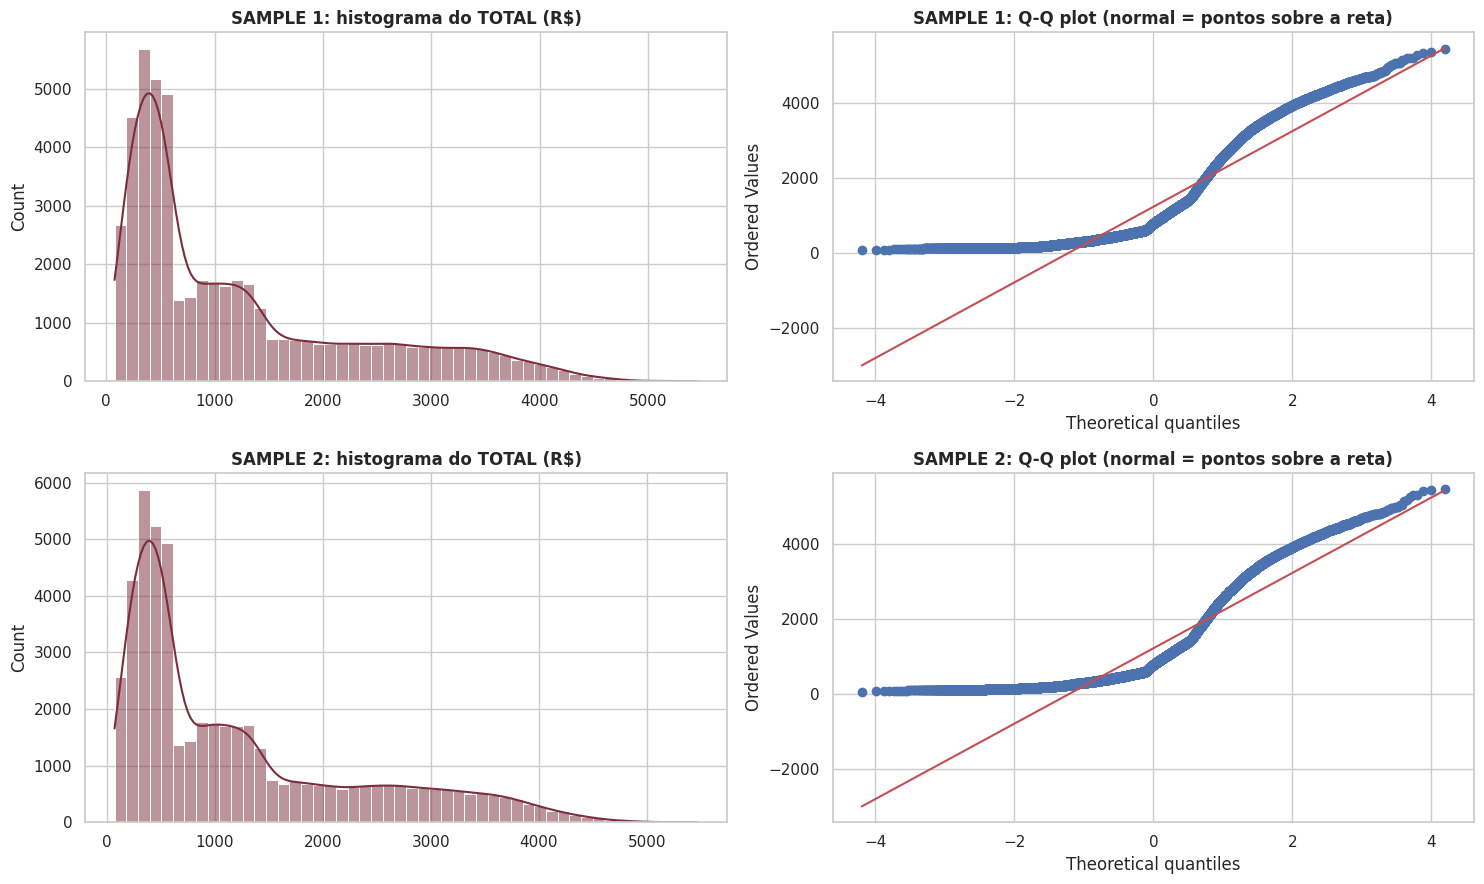

,n,AD estatística,AD valor crítico (5%),Conclusão AD,Shapiro p_value,normaltest p_value,Assimetria,Curtose
Amostra,,,,,,,,
SAMPLE 1,50300,2956.3149,0.787,NÃO normal,0.0,0.0,1.1503,0.2505
SAMPLE 2,50300,2947.4377,0.787,NÃO normal,0.0,0.0,1.1603,0.2897


RESPOSTA: Rejeita H0 -> SAMPLE 1 e SAMPLE 2 NÃO seguem distribuição normal.


In [15]:
def AtividadeA1_3_1(sample_1, sample_2):
    """
    ATIVIDADE A1.3.1 — TESTE DE NORMALIDADE de Anderson-Darling (AD)
    sobre o TOTAL (R$) da SAMPLE 1 e da SAMPLE 2.

    H0: os dados seguem uma distribuição normal.
    H1: os dados NÃO seguem uma distribuição normal.
    Decisão: se a estatística AD > valor crítico (5%) -> rejeita H0.
    Complementos: Shapiro-Wilk e normaltest (D'Agostino), histograma e
    Q-Q plot.

    Returns
    -------
    bool
        True se as duas amostras forem normais.
    """
    linhas = []
    fig, axes = plt.subplots(2, 2, figsize=(15, 9))
    for i, (nome, s) in enumerate([('SAMPLE 1', sample_1), ('SAMPLE 2', sample_2)]):
        x = s[TARGET].to_numpy()

        ad = anderson(x, dist='norm')
        niveis = np.asarray(ad.significance_level, dtype=float)
        if niveis.max() <= 1:                      # compatibilidade entre versões do SciPy
            niveis = niveis * 100
        critico = float(np.asarray(ad.critical_values)[np.argmin(np.abs(niveis - 5))])

        linhas.append({'Amostra': nome, 'n': len(x),
                       'AD estatística': float(ad.statistic), 'AD valor crítico (5%)': critico,
                       'Conclusão AD': 'NÃO normal' if ad.statistic > critico else 'Normal',
                       'Shapiro p_value': shapiro(x[:5000]).pvalue,
                       'normaltest p_value': normaltest(x).pvalue,
                       'Assimetria': stats.skew(x), 'Curtose': stats.kurtosis(x)})

        sns.histplot(x, bins=50, kde=True, ax=axes[i, 0], color='#7B2D3B')
        axes[i, 0].set_title(f'{nome}: histograma do TOTAL (R$)', fontweight='bold')
        stats.probplot(x, dist='norm', plot=axes[i, 1])
        axes[i, 1].set_title(f'{nome}: Q-Q plot (normal = pontos sobre a reta)',
                             fontweight='bold')
    plt.tight_layout()
    plt.show()

    tabela = pd.DataFrame(linhas).set_index('Amostra')
    display(tabela.round(4))

    normais = bool((tabela['Conclusão AD'] == 'Normal').all())
    print('RESPOSTA:', 'as duas amostras são NORMAIS.' if normais else
          'Rejeita H0 -> SAMPLE 1 e SAMPLE 2 NÃO seguem distribuição normal.')
    RESULTADOS['normal'] = normais
    return normais


sao_normais = AtividadeA1_3_1(SAMPLE_1, SAMPLE_2)

#### A1.3.2: Teste de Independência

Nesta ETAPA, você deve fazer o **TESTE DE ANOVA (+ Gráfico Bootstrap) sobre Testes de Independência: p_value** sobre:

*   SAMPLE 1 e SAMPLE 2
*   RESPONDER: Qual o BEST FIT ?

,Estatística,p_value,Decisão
Pearson,0.0093,0.0369,Rejeita H0 (dependentes)
Spearman,0.0085,0.0579,Não rejeita H0 (independentes)
Kendall tau,0.0056,0.0577,Não rejeita H0 (independentes)
Qui-quadrado,9.0282,0.4347,Não rejeita H0 (independentes)


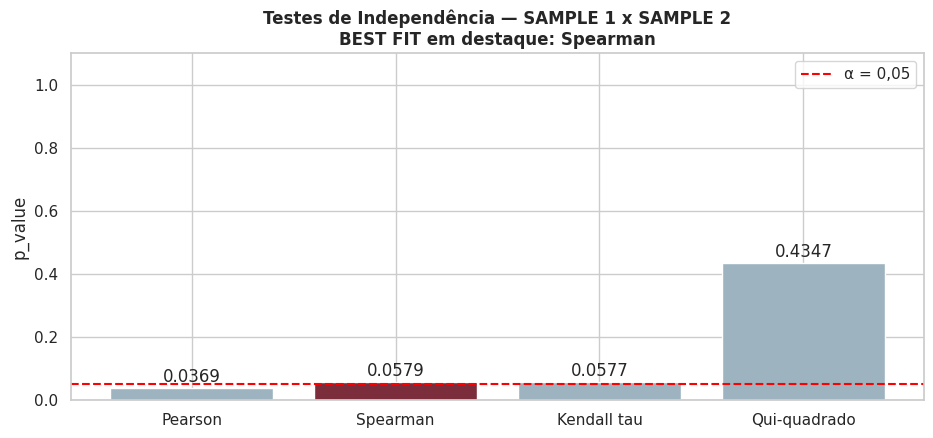

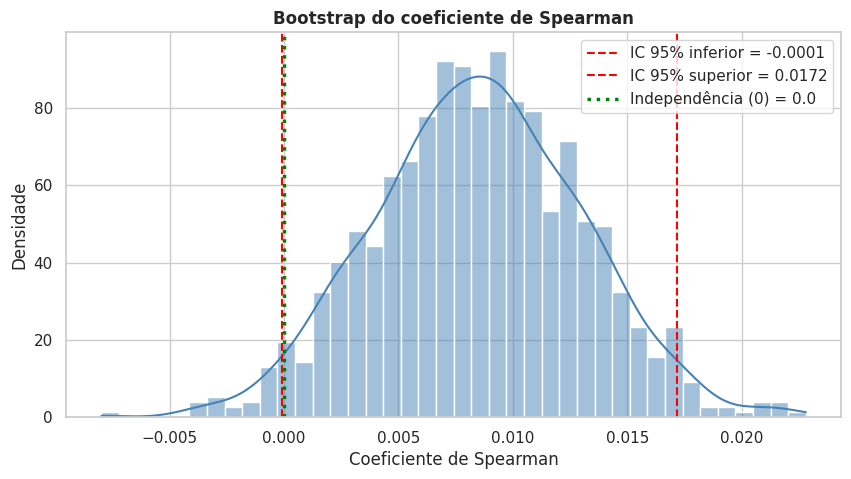

BEST FIT: Spearman (as amostras NÃO são normais)
p_value = 0.0579 | IC 95% bootstrap = [-0.0001 ; 0.0172]
RESPOSTA: SAMPLE 1 e SAMPLE 2 SÃO INDEPENDENTES.


In [16]:
def AtividadeA1_3_2(sample_1, sample_2, normais):
    """
    ATIVIDADE A1.3.2 — TESTES DE INDEPENDÊNCIA entre SAMPLE 1 e SAMPLE 2.

    H0: SAMPLE 1 e SAMPLE 2 são independentes.
    Testes: Pearson, Spearman, Kendall tau e Qui-quadrado (as amostras
    são comparadas posição a posição; o qui-quadrado compara quantas
    notas de cada amostra caem em 10 faixas de valor).
    BEST FIT: Pearson se as amostras forem normais; senão Spearman.
    Gráfico bootstrap: coeficiente do BEST FIT (IC 95% contendo o zero
    = independência).

    Returns
    -------
    pandas.DataFrame
        p_value e decisão de cada teste.
    """
    x = sample_1[TARGET].to_numpy()
    y = sample_2[TARGET].to_numpy()

    pe, sp, ke = pearsonr(x, y), spearmanr(x, y), kendalltau(x, y)
    faixas = np.quantile(np.concatenate([x, y]), np.linspace(0, 1, 11))
    contingencia = np.vstack([np.histogram(x, faixas)[0], np.histogram(y, faixas)[0]])
    chi2, p_chi2, _, _ = chi2_contingency(contingencia)

    tabela = pd.DataFrame({'Estatística': [pe[0], sp[0], ke[0], chi2],
                           'p_value': [pe[1], sp[1], ke[1], p_chi2]},
                          index=['Pearson', 'Spearman', 'Kendall tau', 'Qui-quadrado'])
    tabela['Decisão'] = np.where(tabela['p_value'] > ALPHA, 'Não rejeita H0 (independentes)',
                                 'Rejeita H0 (dependentes)')
    display(tabela.round(4))

    best = 'Pearson' if normais else 'Spearman'
    grafico_pvalores(tabela, 'Testes de Independência — SAMPLE 1 x SAMPLE 2', best)

    # Gráfico bootstrap do coeficiente do BEST FIT
    rng = np.random.default_rng(SEED)
    coef = []
    for _ in range(1000):
        i = rng.integers(0, len(x), len(x))
        coef.append(np.corrcoef(x[i], y[i])[0, 1] if best == 'Pearson'
                    else spearmanr(x[i], y[i])[0])
    low, high = grafico_bootstrap(np.array(coef), f'Bootstrap do coeficiente de {best}',
                                  f'Coeficiente de {best}', rotulo='Independência (0)')

    independentes = tabela.loc[best, 'p_value'] > ALPHA
    print(f'BEST FIT: {best} (as amostras {"são" if normais else "NÃO são"} normais)')
    print(f'p_value = {tabela.loc[best, "p_value"]:.4f} | IC 95% bootstrap = '
          f'[{low:.4f} ; {high:.4f}]')
    print('RESPOSTA: SAMPLE 1 e SAMPLE 2', 'SÃO INDEPENDENTES.' if independentes
          else 'NÃO são independentes.')
    RESULTADOS['independencia'] = (best, independentes, tabela.loc[best, 'p_value'])
    return tabela


tabela_independencia = AtividadeA1_3_2(SAMPLE_1, SAMPLE_2, sao_normais)

**RESPONDER: SAMPLE 1 e SAMPLE 2 são INDEPENDENTES ???**

CONCLUIR / RESPONDER AQUI:
* **Sim, são independentes.** O p_value do Spearman é 0,0579, maior que 0,05, então não rejeitamos H0. O coeficiente de correlação é praticamente zero (por volta de 0,008), ou seja, não existe relação entre os valores das duas amostras.
* O gráfico bootstrap confirma: o intervalo de confiança de 95% do coeficiente vai de -0,0001 a 0,0172 e **contém o zero** (linha verde). Isso era esperado, porque nenhuma nota fiscal se repete entre as duas amostras.

#### A1.3.3: Teste de Distribuição

Nesta ETAPA, você deve fazer o **TESTE DE ANOVA (+ Gráfico Bootstrap) sobre Teste de Mesma Distribuição: p_value** sobre:

*   SAMPLE 1 e SAMPLE 2
*   RESPONDER: Qual o BEST FIT ?

,Estatística,p_value,Decisão
ANOVA (f_oneway),3.673000e-01,0.5445,Não rejeita H0 (mesma distribuição)
Kolmogorov-Smirnov,3.500000e-03,0.9134,Não rejeita H0 (mesma distribuição)
Mann-Whitney U,1.265388e+09,0.9406,Não rejeita H0 (mesma distribuição)
Kruskal-Wallis,5.600000e-03,0.9406,Não rejeita H0 (mesma distribuição)
t pareado (ttest_rel),6.089000e-01,0.5426,Não rejeita H0 (mesma distribuição)


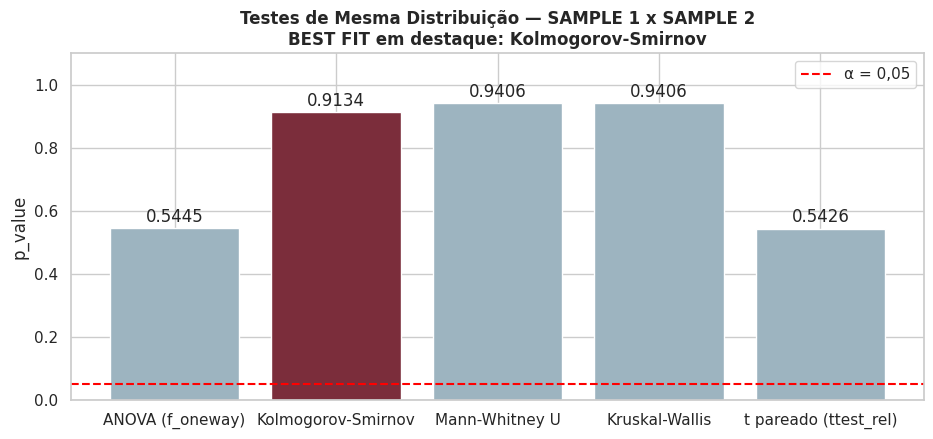

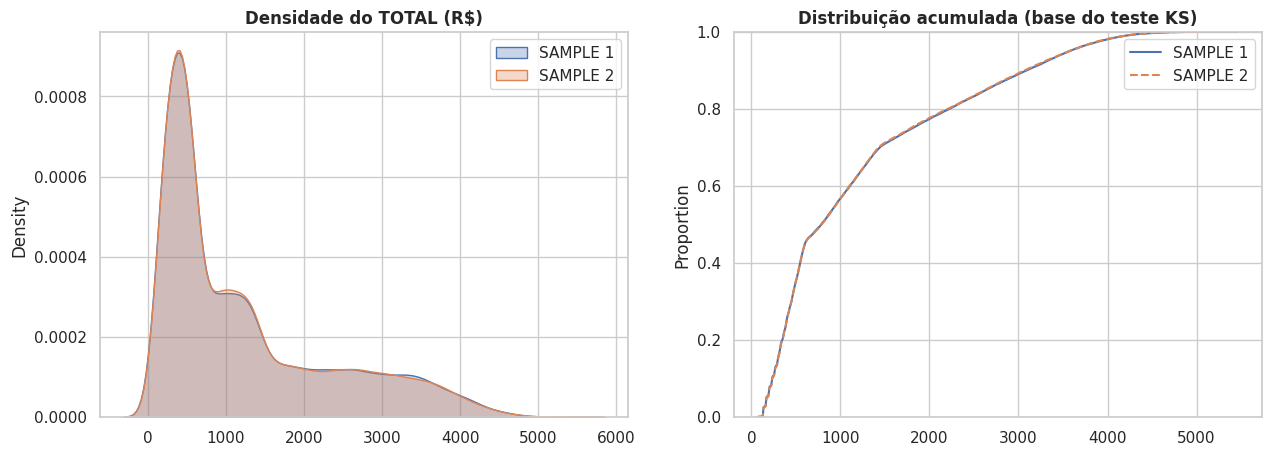

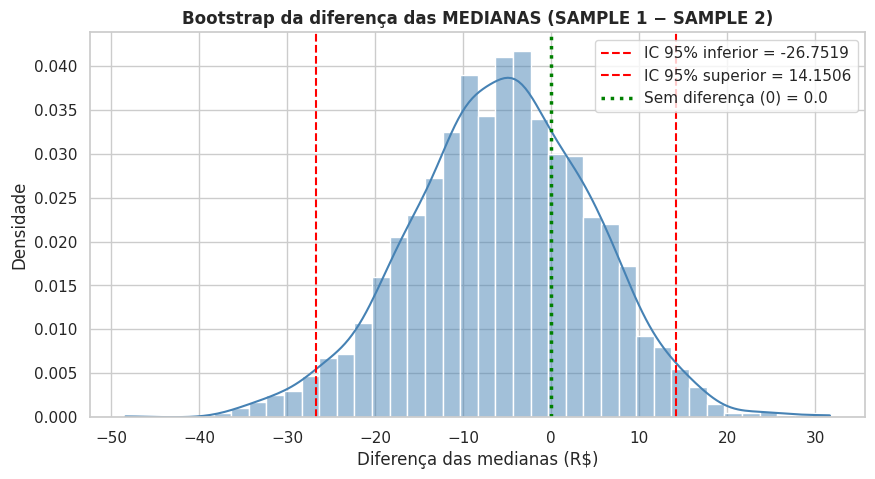

BEST FIT: Kolmogorov-Smirnov | p_value = 0.9134 | IC 95% bootstrap = [-26.75 ; 14.15]
RESPOSTA: SAMPLE 1 e SAMPLE 2 TÊM a MESMA DISTRIBUIÇÃO.


In [17]:
def AtividadeA1_3_3(sample_1, sample_2):
    """
    ATIVIDADE A1.3.3 — TESTES DE MESMA DISTRIBUIÇÃO entre SAMPLE 1 e
    SAMPLE 2.

    H0: SAMPLE 1 e SAMPLE 2 têm a mesma distribuição.
    Testes: ANOVA (f_oneway), Kolmogorov-Smirnov, Mann-Whitney U,
    Kruskal-Wallis e t pareado (ttest_rel, só para comparação: ele é
    para o MESMO cliente medido duas vezes, o que não é o nosso caso).
    BEST FIT: Kolmogorov-Smirnov (compara a distribuição INTEIRA e não
    exige normalidade).
    Gráfico bootstrap: diferença das medianas (SAMPLE 1 - SAMPLE 2).

    Returns
    -------
    pandas.DataFrame
        p_value e decisão de cada teste.
    """
    x = sample_1[TARGET].to_numpy()
    y = sample_2[TARGET].to_numpy()

    testes = {'ANOVA (f_oneway)': f_oneway(x, y),
              'Kolmogorov-Smirnov': ks_2samp(x, y),
              'Mann-Whitney U': mannwhitneyu(x, y),
              'Kruskal-Wallis': kruskal(x, y),
              't pareado (ttest_rel)': ttest_rel(x, y)}
    tabela = pd.DataFrame({'Estatística': [t.statistic for t in testes.values()],
                           'p_value': [t.pvalue for t in testes.values()]},
                          index=list(testes))
    tabela['Decisão'] = np.where(tabela['p_value'] > ALPHA, 'Não rejeita H0 (mesma distribuição)',
                                 'Rejeita H0')
    display(tabela.round(4))

    best = 'Kolmogorov-Smirnov'
    grafico_pvalores(tabela, 'Testes de Mesma Distribuição — SAMPLE 1 x SAMPLE 2', best)

    # As duas distribuições sobrepostas
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    sns.kdeplot(x, ax=axes[0], fill=True, alpha=0.3, label='SAMPLE 1')
    sns.kdeplot(y, ax=axes[0], fill=True, alpha=0.3, label='SAMPLE 2')
    axes[0].set_title('Densidade do TOTAL (R$)', fontweight='bold')
    sns.ecdfplot(x, ax=axes[1], label='SAMPLE 1')
    sns.ecdfplot(y, ax=axes[1], label='SAMPLE 2', linestyle='--')
    axes[1].set_title('Distribuição acumulada (base do teste KS)', fontweight='bold')
    for ax in axes:
        ax.legend()
    plt.show()

    low, high = grafico_bootstrap(bootstrap_diferenca(x, y, func=np.median),
                                  'Bootstrap da diferença das MEDIANAS (SAMPLE 1 − SAMPLE 2)',
                                  'Diferença das medianas (R$)')

    mesma = tabela.loc[best, 'p_value'] > ALPHA
    print(f'BEST FIT: {best} | p_value = {tabela.loc[best, "p_value"]:.4f} | '
          f'IC 95% bootstrap = [{low:.2f} ; {high:.2f}]')
    print('RESPOSTA: SAMPLE 1 e SAMPLE 2', 'TÊM a MESMA DISTRIBUIÇÃO.' if mesma
          else 'NÃO têm a mesma distribuição.')
    RESULTADOS['distribuicao'] = (best, mesma, tabela.loc[best, 'p_value'])
    return tabela


tabela_distribuicao = AtividadeA1_3_3(SAMPLE_1, SAMPLE_2)

**RESPONDER: SAMPLE 1 e SAMPLE 2 tem a MESMA DISTRIBUIÇÃO DOS DADOS ???**

CONCLUIR / RESPONDER AQUI:
* **Sim, têm a mesma distribuição.** O p_value do Kolmogorov-Smirnov é 0,9134, maior que 0,05, então não rejeitamos H0. Os outros testes (ANOVA, Mann-Whitney e Kruskal-Wallis) concordam, e nos gráficos de densidade e de distribuição acumulada as curvas da SAMPLE 1 e da SAMPLE 2 praticamente se sobrepõem.
* O gráfico bootstrap da diferença das medianas tem intervalo de confiança de 95% de [-26,75 ; 14,15] e **contém o zero** (linha verde): não há diferença entre as amostras.

#### A1.3.4: Teste das Médias Amostrais

Nesta ETAPA, você deve fazer o **TESTE DE ANOVA (+ Gráfico Bootstrap) sobre Teste das Médias Amostrais: p_value** sobre:

*   SAMPLE 1 e SAMPLE 2
*   RESPONDER: Qual o BEST FIT ?

,Estatística,p_value,Decisão
Levene (variâncias),1.0980,0.2947,Não rejeita H0 (iguais)
ANOVA (f_oneway),0.3673,0.5445,Não rejeita H0 (iguais)
t de Student,0.6060,0.5445,Não rejeita H0 (iguais)
t de Welch,0.6060,0.5445,Não rejeita H0 (iguais)


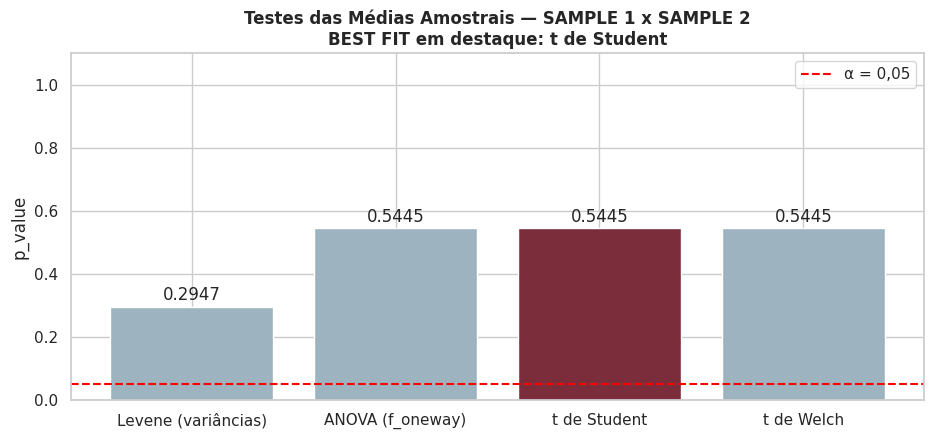

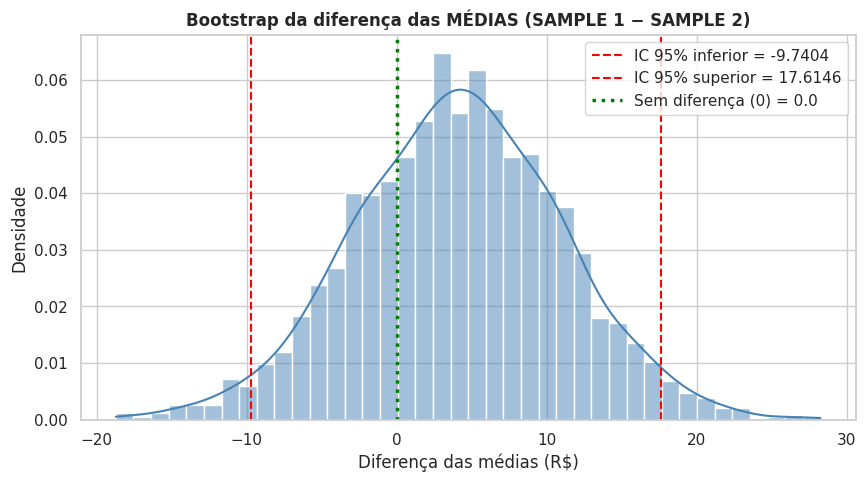

Média SAMPLE 1 = R$ 1232.83 | Média SAMPLE 2 = R$ 1228.63
BEST FIT: t de Student | p_value = 0.5445 | IC 95% bootstrap = [-9.74 ; 17.61]
RESPOSTA: SAMPLE 1 e SAMPLE 2 TÊM as MESMAS MÉDIAS.


In [18]:
def AtividadeA1_3_4(sample_1, sample_2):
    """
    ATIVIDADE A1.3.4 — TESTES DAS MÉDIAS AMOSTRAIS entre SAMPLE 1 e
    SAMPLE 2.

    H0: as médias de SAMPLE 1 e SAMPLE 2 são iguais.
    Testes: Levene (as variâncias são iguais?), ANOVA (f_oneway),
    t de Student (ttest_ind) e t de Welch (ttest_ind, equal_var=False).
    BEST FIT: t de Student se o Levene indicar variâncias iguais; senão,
    t de Welch. Com amostras grandes, o Teorema Central do Limite
    garante que o teste t funciona mesmo sem normalidade.
    Gráfico bootstrap: diferença das médias (SAMPLE 1 - SAMPLE 2).

    Returns
    -------
    pandas.DataFrame
        p_value e decisão de cada teste.
    """
    x = sample_1[TARGET].to_numpy()
    y = sample_2[TARGET].to_numpy()

    testes = {'Levene (variâncias)': levene(x, y),
              'ANOVA (f_oneway)': f_oneway(x, y),
              't de Student': ttest_ind(x, y, equal_var=True),
              't de Welch': ttest_ind(x, y, equal_var=False)}
    tabela = pd.DataFrame({'Estatística': [t.statistic for t in testes.values()],
                           'p_value': [t.pvalue for t in testes.values()]},
                          index=list(testes))
    tabela['Decisão'] = np.where(tabela['p_value'] > ALPHA, 'Não rejeita H0 (iguais)',
                                 'Rejeita H0 (diferentes)')
    display(tabela.round(4))

    best = 't de Student' if tabela.loc['Levene (variâncias)', 'p_value'] > ALPHA else 't de Welch'
    grafico_pvalores(tabela, 'Testes das Médias Amostrais — SAMPLE 1 x SAMPLE 2', best)

    low, high = grafico_bootstrap(bootstrap_diferenca(x, y, func=np.mean),
                                  'Bootstrap da diferença das MÉDIAS (SAMPLE 1 − SAMPLE 2)',
                                  'Diferença das médias (R$)')

    iguais = tabela.loc[best, 'p_value'] > ALPHA
    print(f'Média SAMPLE 1 = R$ {x.mean():.2f} | Média SAMPLE 2 = R$ {y.mean():.2f}')
    print(f'BEST FIT: {best} | p_value = {tabela.loc[best, "p_value"]:.4f} | '
          f'IC 95% bootstrap = [{low:.2f} ; {high:.2f}]')
    print('RESPOSTA: SAMPLE 1 e SAMPLE 2', 'TÊM as MESMAS MÉDIAS.' if iguais
          else 'NÃO têm as mesmas médias.')
    RESULTADOS['medias'] = (best, iguais, x.mean(), y.mean())
    return tabela


tabela_medias = AtividadeA1_3_4(SAMPLE_1, SAMPLE_2)

**RESPONDER: SAMPLE 1 e SAMPLE 2 tem as MESMAS MÉDIAS AMOSTRAIS ???**

CONCLUIR / RESPONDER AQUI:
* **Sim, têm as mesmas médias.** A média da SAMPLE 1 é R$ 1.232,83 e a da SAMPLE 2 é R$ 1.228,63, uma diferença de apenas R$ 4,20 (menos de 0,4%). O p_value do teste t é 0,5445, bem maior que 0,05, então não rejeitamos H0: as médias são estatisticamente iguais.
* O gráfico bootstrap da diferença das médias tem intervalo de confiança de 95% de [-9,74 ; 17,61] e **contém o zero** (linha verde). Conclusão geral da A1.3: duas amostras do tamanho ideal são independentes, têm a mesma distribuição e as mesmas médias, então o tamanho ideal de 50.300 notas fiscais é **suficiente e representativo** da população.

##Atividade A2 ([Link](https://colab.research.google.com/drive/1w-72bl_qBnGIR8y9zcGYNcpar9b2JdwA?usp=sharing)): Estatística descritiva

###Atividade A2.1: Analisar as variáveis Quantitativas

1. ESTATÍSTICA DESCRITIVA DAS VARIÁVEIS QUANTITATIVAS


,min,std,25%,mode,50%,mean,75%,range,max
DEPENDENTES,0.00,0.96,0.00,1.00,1.00,1.06,1.00,4.00,4.00
RENDA BRUTO (R$),1758.25,6379.94,3228.06,3214.27,3317.26,6887.60,7771.74,31955.80,33714.05
NOTA DE SATISFAÇÃO (%),68.68,1.32,68.68,68.68,68.68,68.95,68.68,23.74,92.42
MEAN: alcohol,9.18,0.81,12.46,9.18,13.00,13.00,13.55,7.60,16.78
MEAN: malic_acid,-3.83,1.11,1.58,-3.83,2.34,2.34,3.09,11.53,7.70
MEAN: ash,1.14,0.27,2.18,1.14,2.37,2.37,2.55,2.51,3.65
MEAN: alcalinity_of_ash,4.29,3.33,17.25,4.29,19.50,19.49,21.74,31.17,35.47
MEAN: magnesium,30.95,14.26,90.09,30.95,99.72,99.72,109.34,134.83,165.78
MEAN: total_phenols,-1.05,0.62,1.87,-1.05,2.29,2.29,2.71,6.67,5.62
MEAN: flavanoids,-3.24,1.00,1.36,-3.24,2.03,2.03,2.70,10.12,6.87



2. TOTAL (R$) POR TIPO DA CONTA


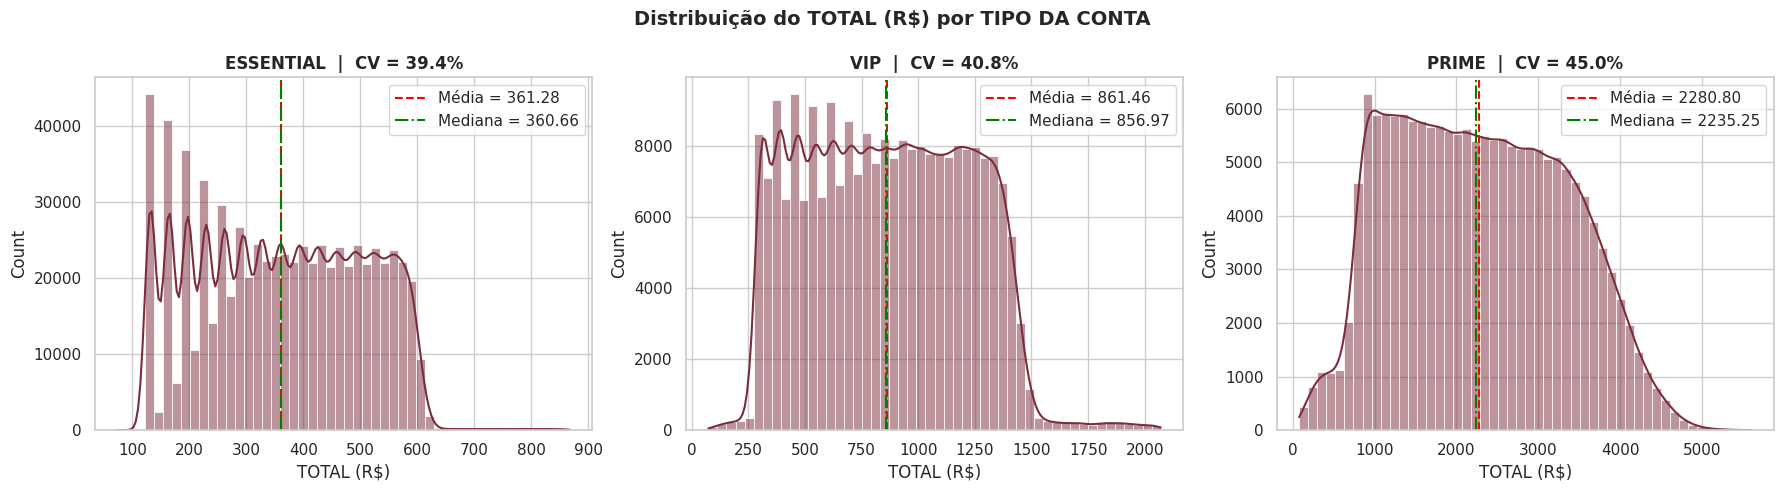

,Média,Mediana,Moda,Desvio-padrão,CV (%),Assimetria,Curtose
ESSENTIAL,361.2828,360.66,131.34,142.3282,39.3952,0.0519,-1.0678
VIP,861.4646,856.97,315.79,351.4111,40.7923,0.1468,-0.8197
PRIME,2280.8036,2235.25,921.36,1027.0306,45.0293,0.1604,-0.8923


In [19]:
def AtividadeA2_1(df):
    """
    ATIVIDADE A2.1 — Estatística descritiva das variáveis QUANTITATIVAS
    (base sem outliers).

    1. Tabela com min, std, 25%, mode, 50%, mean, 75%, range e max de
       todas as variáveis numéricas (NOTA FISCAL fica de fora: é código).
    2. Entre outros: média, mediana, moda, CV, assimetria e curtose do
       TOTAL (R$) por TIPO DA CONTA, com histogramas.

    Parameters
    ----------
    df : pandas.DataFrame
        Base sem outliers (table_limpo).

    Returns
    -------
    pandas.DataFrame
        Tabela de estatísticas descritivas.
    """
    quantitativas = [c for c in df.select_dtypes('number').columns if c != 'NOTA FISCAL']

    # 1. TABELA DE MEDIDAS
    medidas = {}
    for c in quantitativas:
        x = df[c]
        medidas[c] = {'min': x.min(), 'std': x.std(), '25%': x.quantile(0.25),
                      'mode': x.mode().iloc[0], '50%': x.median(), 'mean': x.mean(),
                      '75%': x.quantile(0.75), 'range': x.max() - x.min(), 'max': x.max()}
    tabela = pd.DataFrame(medidas).T
    print('1. ESTATÍSTICA DESCRITIVA DAS VARIÁVEIS QUANTITATIVAS')
    display(tabela.round(2))

    # 2. TOTAL (R$) POR TIPO DA CONTA
    print('\n2. TOTAL (R$) POR TIPO DA CONTA')
    resumo = {}
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    for ax, c in zip(axes, CONTAS):
        x = df.loc[df[ESTRATO] == c, TARGET]
        resumo[c] = {'Média': x.mean(), 'Mediana': x.median(), 'Moda': x.mode().iloc[0],
                     'Desvio-padrão': x.std(), 'CV (%)': x.std() / x.mean() * 100,
                     'Assimetria': stats.skew(x), 'Curtose': stats.kurtosis(x)}
        sns.histplot(x, bins=50, kde=True, ax=ax, color='#7B2D3B')
        ax.axvline(x.mean(), color='red', linestyle='--', label=f'Média = {x.mean():.2f}')
        ax.axvline(x.median(), color='green', linestyle='-.', label=f'Mediana = {x.median():.2f}')
        ax.set_title(f'{c}  |  CV = {resumo[c]["CV (%)"]:.1f}%', fontweight='bold')
        ax.legend()
    plt.suptitle('Distribuição do TOTAL (R$) por TIPO DA CONTA', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
    resumo = pd.DataFrame(resumo).T
    display(resumo.round(4))

    RESULTADOS['resumo_contas'] = resumo
    return tabela


tabela_quantitativas = AtividadeA2_1(table_limpo)

###Atividade A2.2: Analisar as variáveis Qualitativas

1. GRÁFICOS DE PARETO


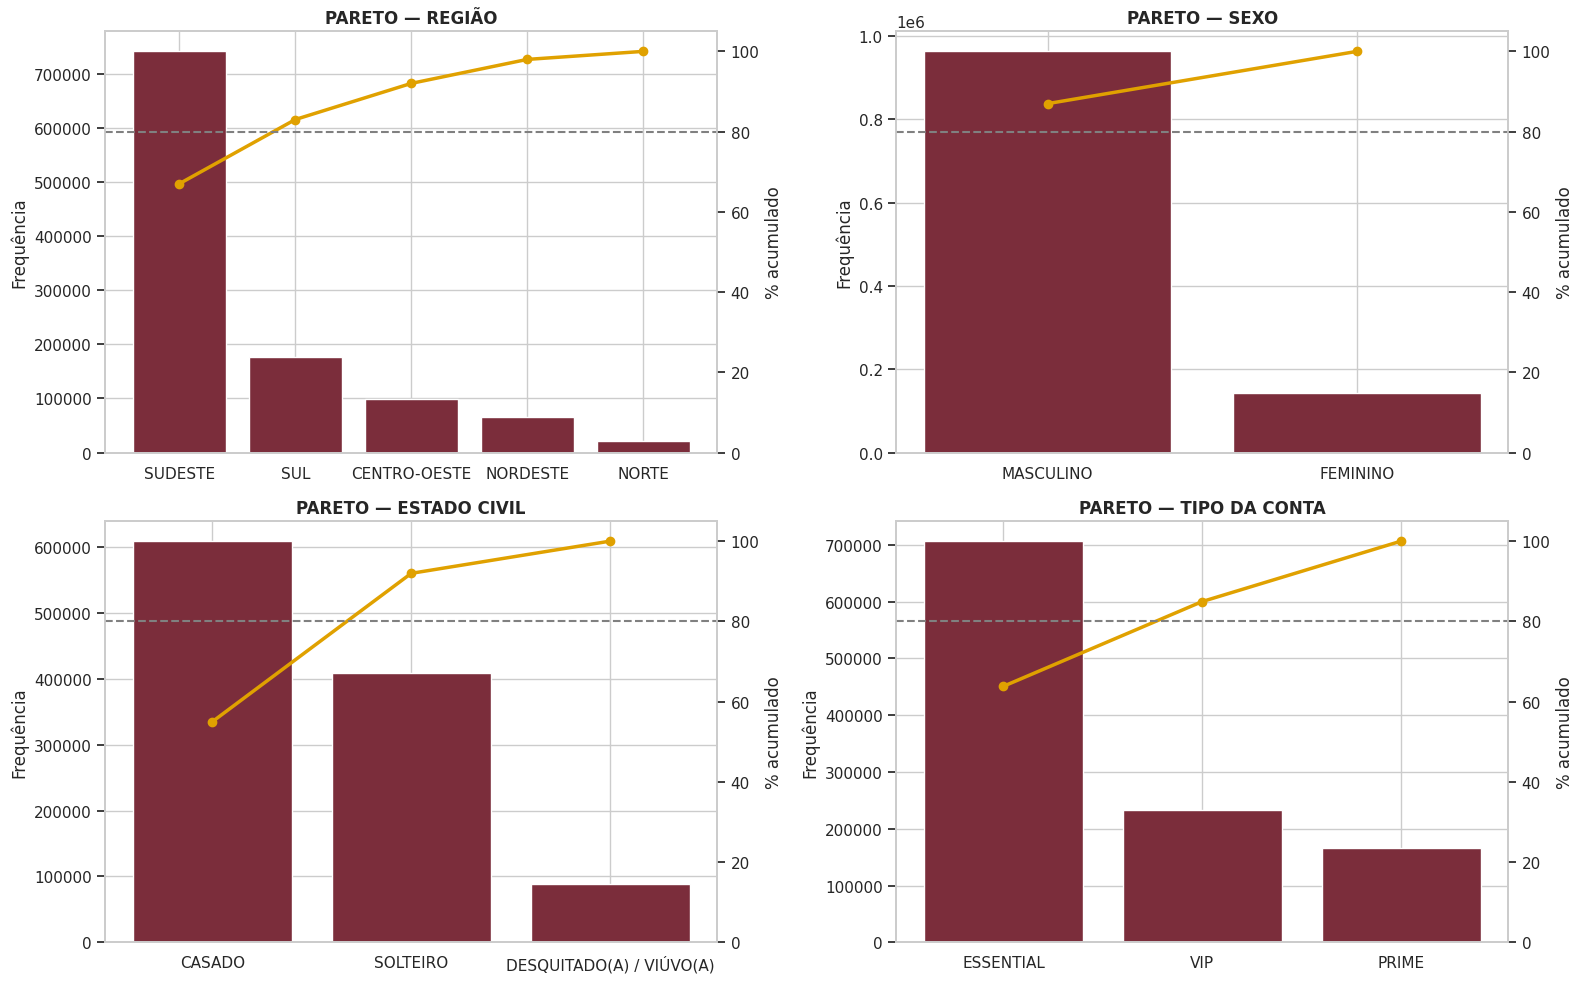

2. BOXPLOTS


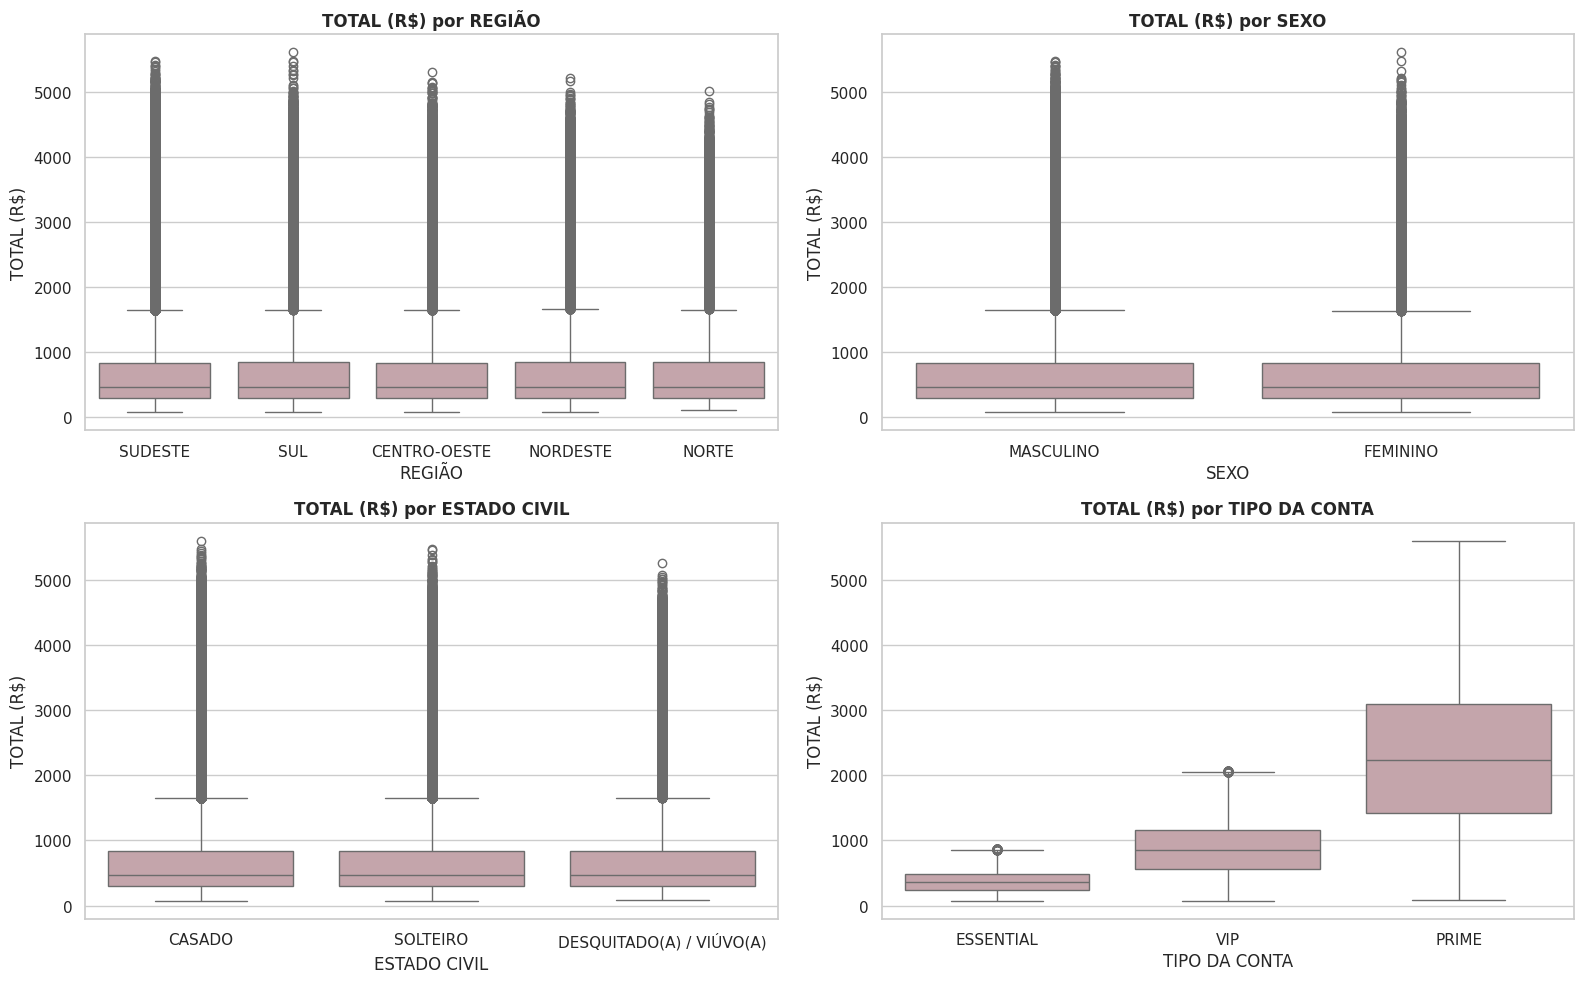

3. FREQUÊNCIA (%) E GASTO MÉDIO POR CATEGORIA


,count,mean,median,%
REGIÃO,,,,
SUDESTE,741978,755.81,468.74,67.01
SUL,177212,756.99,468.45,16.01
CENTRO-OESTE,99708,754.09,467.37,9.01
NORDESTE,66170,754.80,469.51,5.98
NORTE,22150,759.50,470.56,2.00


,count,mean,median,%
SEXO,,,,
MASCULINO,963058,756.17,469.08,86.98
FEMININO,144160,753.80,465.84,13.02


,count,mean,median,%
ESTADO CIVIL,,,,
CASADO,609160,757.77,470.35,55.02
SOLTEIRO,409186,751.95,464.75,36.96
DESQUITADO(A) / VIÚVO(A),88872,760.78,473.72,8.03


,count,mean,median,%
TIPO DA CONTA,,,,
ESSENTIAL,706693,361.28,360.66,63.83
VIP,233864,861.46,856.97,21.12
PRIME,166661,2280.80,2235.25,15.05


In [20]:
def AtividadeA2_2(df):
    """
    ATIVIDADE A2.2 — Estatística descritiva das variáveis QUALITATIVAS
    (REGIÃO, SEXO, ESTADO CIVIL e TIPO DA CONTA), base sem outliers.

    1. PARETO: barras = frequência (ordem decrescente); linha = % acumulado.
    2. BOXPLOT: TOTAL (R$) em cada categoria.
    3. Entre outros: tabela de frequência e gasto médio por categoria.

    Parameters
    ----------
    df : pandas.DataFrame
        Base sem outliers (table_limpo).
    """
    qualitativas = ['REGIÃO', 'SEXO', 'ESTADO CIVIL', 'TIPO DA CONTA']

    # 1. PARETO
    print('1. GRÁFICOS DE PARETO')
    fig, axes = plt.subplots(2, 2, figsize=(16, 10))
    for ax, q in zip(axes.flat, qualitativas):
        freq = df[q].value_counts()
        acumulado = freq.cumsum() / freq.sum() * 100
        ax.bar(freq.index, freq.values, color='#7B2D3B')
        ax.set_ylabel('Frequência')
        ax2 = ax.twinx()
        ax2.plot(freq.index, acumulado.values, color='#E0A100', marker='o', linewidth=2.5)
        ax2.axhline(80, color='gray', linestyle='--')
        ax2.set_ylim(0, 105)
        ax2.set_ylabel('% acumulado')
        ax2.grid(False)
        ax.set_title(f'PARETO — {q}', fontweight='bold')
    plt.tight_layout()
    plt.show()

    # 2. BOXPLOT
    print('2. BOXPLOTS')
    fig, axes = plt.subplots(2, 2, figsize=(16, 10))
    for ax, q in zip(axes.flat, qualitativas):
        sns.boxplot(data=df, x=q, y=TARGET, order=df[q].value_counts().index,
                    color='#C9A0A8', ax=ax)
        ax.set_title(f'TOTAL (R$) por {q}', fontweight='bold')
    plt.tight_layout()
    plt.show()

    # 3. FREQUÊNCIA E GASTO MÉDIO
    print('3. FREQUÊNCIA (%) E GASTO MÉDIO POR CATEGORIA')
    for q in qualitativas:
        t = df.groupby(q)[TARGET].agg(['count', 'mean', 'median'])
        t['%'] = t['count'] / t['count'].sum() * 100
        display(t.sort_values('count', ascending=False).round(2))


AtividadeA2_2(table_limpo)

##Atividade A3: Resultado da Pesquisa de Satisfação

Fazer o resultado da Pesquisa de satisfação do cliente em porcentagem (%):
* Geral
* Por Sexo

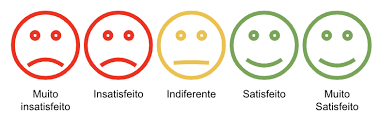

###Atividade A3.1: Discretizar a Variável Qualitativa (OPINIÃO DO CLIENTE)

In [21]:
CLASSIFICACAO = {1: 'Muito Insatisfeito', 2: 'Insatisfeito', 3: 'Indiferente',
                 4: 'Satisfeito', 5: 'Muito Satisfeito'}

# Palavra-chave de cada uma das 25 opiniões (texto sem acento e minúsculo) -> NOTA
# A ordem importa: as negativas vêm primeiro ("nao gostei" antes de "gostei").
PALAVRAS_CHAVE = [
    ('faltou qualidade', 1), ('experiencia ruim', 1), ('nao gostei', 1),
    ('deixou a desejar', 1), ('chegou atrasado', 1),
    ('atendimento comum', 2), ('nada demais', 2), ('experiencia regular', 2),
    ('foi aceitavel', 2), ('razoavel', 2),
    ('nada digno de nota', 3), ('foi indiferente', 3), ('nao tenho muito a dizer', 3),
    ('sem opiniao formada', 3), ('opiniao neutra', 3),
    ('servico impecavel', 5), ('superou expectativas', 5), ('otimo', 5),
    ('produto perfeito', 5), ('excelente experiencia', 5),
    ('entrega foi boa', 4), ('funcionou bem', 4), ('fiquei satisfeito', 4),
    ('servico eficiente', 4), ('gostei do atendimento', 4),
]


def AtividadeA3_1(df):
    """
    ATIVIDADE A3.1 — Discretizar a OPINIÃO DO CLIENTE em NOTA (1 a 5).

    Cada frase é padronizada (sem acentos, minúscula, sem espaços
    duplos) e recebe a NOTA da primeira palavra-chave encontrada.
    Cria as colunas NOTA e CLASSIFICAÇÃO.

    Parameters
    ----------
    df : pandas.DataFrame
        Base de dados completa (table1).

    Returns
    -------
    pandas.DataFrame
        Base com as colunas NOTA e CLASSIFICAÇÃO.
    """
    def padronizar(texto):
        texto = unicodedata.normalize('NFKD', ' '.join(str(texto).split()))
        return ''.join(ch for ch in texto if not unicodedata.combining(ch)).lower()

    def nota(texto):
        t = padronizar(texto)
        for chave, n in PALAVRAS_CHAVE:
            if chave in t:
                return n
        return np.nan

    df = df.copy()
    mapa = {frase: nota(frase) for frase in df['OPINIÃO DO CLIENTE'].unique()}
    df['NOTA'] = df['OPINIÃO DO CLIENTE'].map(mapa)
    print(f'Frases distintas: {len(mapa)} | sem classificação: {int(df["NOTA"].isna().sum())}')
    df['NOTA'] = df['NOTA'].astype(int)
    df['CLASSIFICAÇÃO'] = df['NOTA'].map(CLASSIFICACAO)

    tabela = (df.groupby(['NOTA', 'CLASSIFICAÇÃO', 'OPINIÃO DO CLIENTE']).size()
              .rename('Quantidade').reset_index().set_index(['NOTA', 'CLASSIFICAÇÃO']))
    display(tabela)
    return df


table1 = AtividadeA3_1(table1)

Frases distintas: 25 | sem classificação: 0


OPINIÃO DO CLIENTE  \
NOTA CLASSIFICAÇÃO                                                           
1    Muito Insatisfeito                Não gostei do atendimento na UVVine   
     Muito Insatisfeito                  Produto chegou atrasado na UVVine   
     Muito Insatisfeito  Senti que faltou qualidade no atendimento da U...   
     Muito Insatisfeito                 Serviço deixou a desejar na UVVine   
     Muito Insatisfeito             Tive uma experiência ruim com a UVVine   
2    Insatisfeito        Atendimento comum, poderia melhorar em cordial...   
     Insatisfeito        Experiência regular, não atendeu a política de...   
     Insatisfeito                   Foi aceitável, esperava mais da UVVine   
     Insatisfeito                   Nada demais, serviço regular na UVVine   
     Insatisfeito        Razoável, com margem de melhora no preço médio...   
3    Indiferente         Compro exponenciamente, opinião neutra sobre U...   
     Indiferente            Foi indiferente minha experiência com a UVVine   
     Indiferente                           Nada digno de nota com a UVVine   
     Indiferente                    Não tenho muito a dizer sobre a UVVine   
     Indiferente                        Sem opinião formada sobre a UVVine   
4    Satisfeito                         Entrega foi boa e rápida na UVVine   
     Satisfeito                  Fiquei satisfeito com o serviço da UVVine   
     Satisfeito          Funcionou bem e me atendeu no prazo certo a UV...   
     Satisfeito                 Gostei do atendimento prestado pela UVVine   
     Satisfeito              Serviço eficiente, recomendo o clube:  UVVine   
5    Muito Satisfeito      Excelente experiência, recomendo muito a UVVine   
     Muito Satisfeito    Produto perfeito, chegou antes do prazo de pre...   
     Muito Satisfeito           Serviço impecável, adorei o clube:  UVVine   
     Muito Satisfeito         Superou expectativas o atendimento na UVVine   
     Muito Satisfeito    Ótimo! Tudo ocorreu maravilhosamente bem com a...   

                         Quantidade  
NOTA CLASSIFICAÇÃO                   
1    Muito Insatisfeito        2251  
     Muito Insatisfeito        2179  
     Muito Insatisfeito        2287  
     Muito Insatisfeito        2225  
     Muito Insatisfeito        2258  
2    Insatisfeito              9056  
     Insatisfeito              9018  
     Insatisfeito              8857  
     Insatisfeito              9033  
     Insatisfeito              8836  
3    Indiferente              33436  
     Indiferente              33673  
     Indiferente              33859  
     Indiferente              33549  
     Indiferente              33483  
4    Satisfeito              172818  
     Satisfeito              172523  
     Satisfeito              172639  
     Satisfeito              172182  
     Satisfeito              172238  
5    Muito Satisfeito          6635  
     Muito Satisfeito          6657  
     Muito Satisfeito          6825  
     Muito Satisfeito          6762  
     Muito Satisfeito          6721

###Atividade A3.2: Análise Bootstrap do resultado da Pesquisa de Satisfação

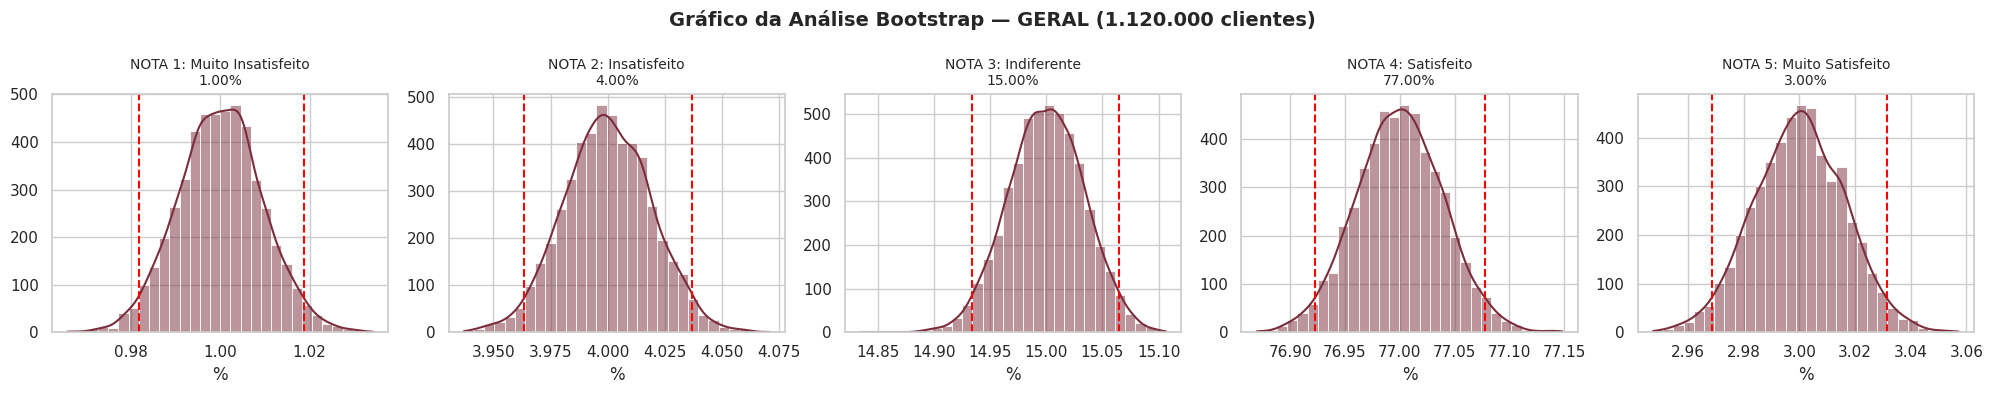

ERRO-PADRÃO E INTERVALO DE CONFIANÇA — GERAL


,Classificação,%,Erro-padrão (p.p.),IC 95% inferior,IC 95% superior
NOTA,,,,,
1,Muito Insatisfeito,1.0,0.0094,0.9819,1.0187
2,Insatisfeito,4.0,0.0190,3.9632,4.0367
3,Indiferente,15.0,0.0336,14.9340,15.0646
4,Satisfeito,77.0,0.0395,76.9225,77.0773
5,Muito Satisfeito,3.0,0.0162,2.9685,3.0314


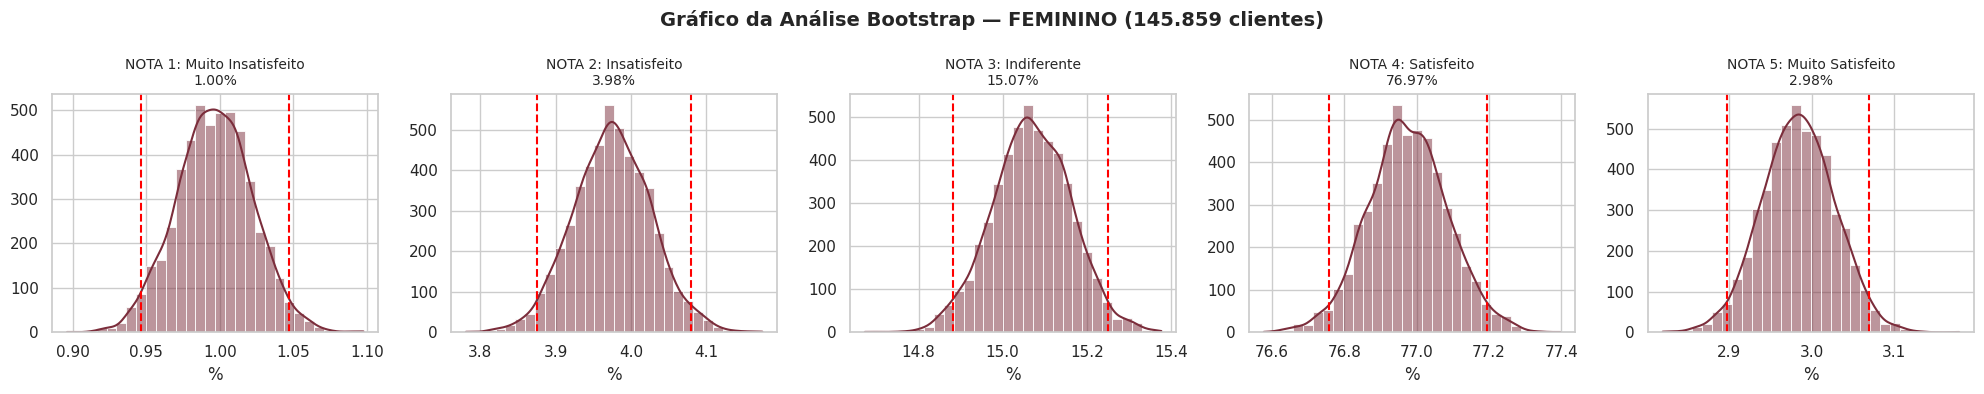

ERRO-PADRÃO E INTERVALO DE CONFIANÇA — FEMININO


,Classificação,%,Erro-padrão (p.p.),IC 95% inferior,IC 95% superior
NOTA,,,,,
1,Muito Insatisfeito,0.9962,0.0258,0.9461,1.0469
2,Insatisfeito,3.9758,0.0517,3.8756,4.0793
3,Indiferente,15.0693,0.0934,14.8822,15.2497
4,Satisfeito,76.9743,0.1103,76.7563,77.1944
5,Muito Satisfeito,2.9844,0.0440,2.8973,3.0694


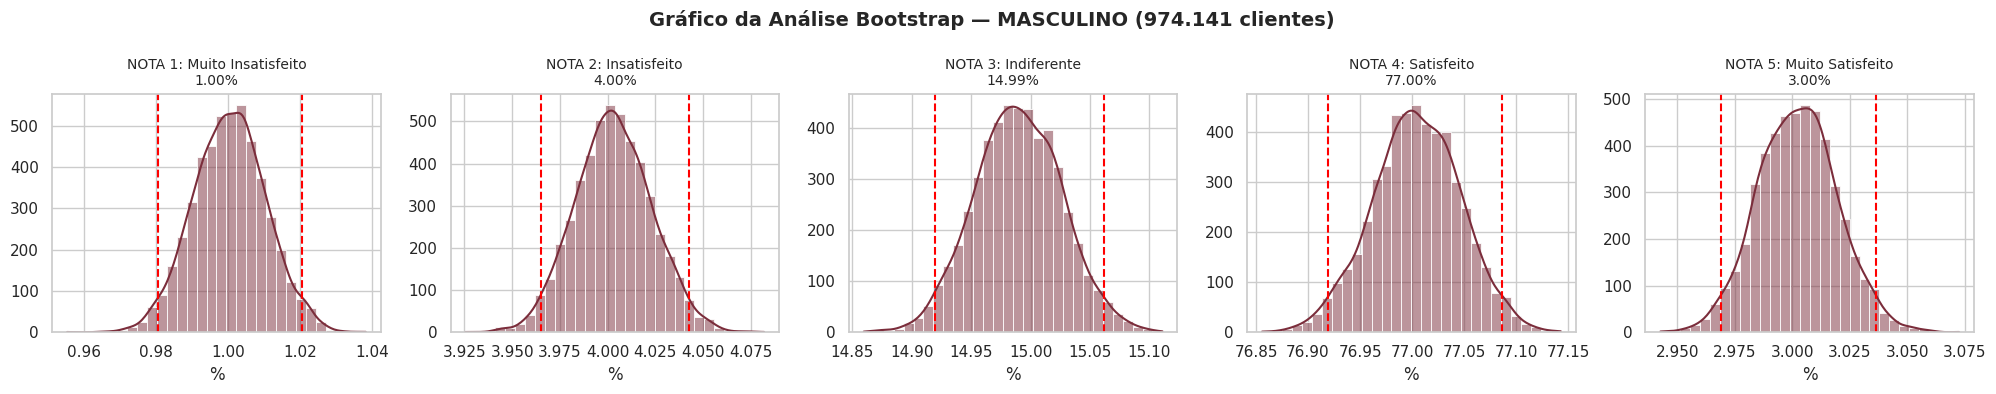

ERRO-PADRÃO E INTERVALO DE CONFIANÇA — MASCULINO


,Classificação,%,Erro-padrão (p.p.),IC 95% inferior,IC 95% superior
NOTA,,,,,
1,Muito Insatisfeito,1.0006,0.0100,0.9808,1.0207
2,Insatisfeito,4.0036,0.0200,3.9652,4.0424
3,Indiferente,14.9896,0.0364,14.9193,15.0615
4,Satisfeito,77.0038,0.0422,76.9194,77.0867
5,Muito Satisfeito,3.0023,0.0172,2.9692,3.0364


In [22]:
def AtividadeA3_2(df, n_boot=5000):
    """
    ATIVIDADE A3.2 — ANÁLISE BOOTSTRAP da Pesquisa de Satisfação
    (GERAL, FEMININO e MASCULINO).

    Para cada NOTA: % de clientes, ERRO-PADRÃO e INTERVALO DE
    CONFIANÇA de 95%, com o gráfico bootstrap.
    Como só existem 5 respostas, reamostrar os clientes com reposição é
    o mesmo que sortear quantos caem em cada nota (distribuição
    multinomial) — muito mais rápido com 1,12 milhão de clientes.

    Parameters
    ----------
    df : pandas.DataFrame
        Base com a coluna NOTA (A3.1).
    n_boot : int
        Número de reamostragens.

    Returns
    -------
    dict
        Tabela bootstrap de cada grupo.
    """
    rng = np.random.default_rng(SEED)
    grupos = {'GERAL': df, 'FEMININO': df[df['SEXO'] == 'FEMININO'],
              'MASCULINO': df[df['SEXO'] == 'MASCULINO']}
    tabelas = {}
    for nome, base in grupos.items():
        n = len(base)
        p = base['NOTA'].value_counts(normalize=True).reindex(range(1, 6), fill_value=0).values
        reamostras = rng.multinomial(n, p, size=n_boot) / n * 100    # % em cada reamostra

        tabela = pd.DataFrame({'Classificação': list(CLASSIFICACAO.values()),
                               '%': p * 100,
                               'Erro-padrão (p.p.)': reamostras.std(axis=0, ddof=1),
                               'IC 95% inferior': np.percentile(reamostras, 2.5, axis=0),
                               'IC 95% superior': np.percentile(reamostras, 97.5, axis=0)},
                              index=pd.Index(range(1, 6), name='NOTA'))
        tabelas[nome] = tabela

        fig, axes = plt.subplots(1, 5, figsize=(20, 4))
        for k, ax in zip(range(1, 6), axes):
            sns.histplot(reamostras[:, k - 1], bins=30, kde=True, ax=ax, color='#7B2D3B')
            ax.axvline(tabela.loc[k, 'IC 95% inferior'], color='red', linestyle='--')
            ax.axvline(tabela.loc[k, 'IC 95% superior'], color='red', linestyle='--')
            ax.set_title(f'NOTA {k}: {CLASSIFICACAO[k]}\n{tabela.loc[k, "%"]:.2f}%', fontsize=10)
            ax.set_xlabel('%')
            ax.set_ylabel('')
        fig.suptitle(f'Gráfico da Análise Bootstrap — {nome} ({n:,} clientes)'.replace(',', '.'),
                     fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.show()
        print(f'ERRO-PADRÃO E INTERVALO DE CONFIANÇA — {nome}')
        display(tabela.round(4))

    RESULTADOS['bootstrap_satisfacao'] = tabelas
    return tabelas


tabelas_bootstrap = AtividadeA3_2(table1)

###Atividade A3.3: Resultado Final da Pesquisa de Satisfação

1. RESULTADO FINAL DA PESQUISA DE SATISFAÇÃO (%)


,GERAL,FEMININO,MASCULINO
NOTA 1: Muito Insatisfeito,1.0,1.00,1.00
NOTA 2: Insatisfeito,4.0,3.98,4.00
NOTA 3: Indiferente,15.0,15.07,14.99
NOTA 4: Satisfeito,77.0,76.97,77.00
NOTA 5: Muito Satisfeito,3.0,2.98,3.00


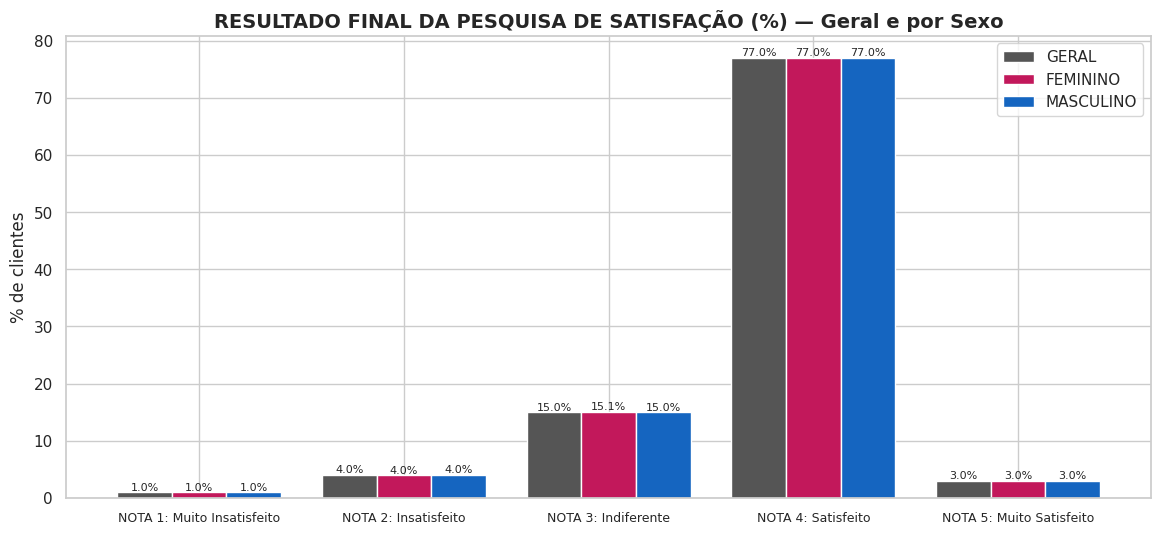

3. INDICADORES


,GERAL,FEMININO,MASCULINO
% Satisfeitos (notas 4 e 5),80.00,79.96,80.01
% Indiferentes (nota 3),15.00,15.07,14.99
% Insatisfeitos (notas 1 e 2),5.00,4.97,5.00
Nota média (1 a 5),3.77,3.77,3.77


4. Qui-quadrado SEXO x NOTA: p_value = 0.9159 -> NÃO há diferença de satisfação entre os sexos.


In [23]:
def AtividadeA3_3(df):
    """
    ATIVIDADE A3.3 — RESULTADO FINAL da Pesquisa de Satisfação em %:
    GERAL e POR SEXO.

    1. Tabela com o % de cada NOTA (Geral, Feminino, Masculino).
    2. Gráfico de barras.
    3. Indicadores: % satisfeitos (notas 4+5), % indiferentes (3),
       % insatisfeitos (1+2) e nota média.
    4. Qui-quadrado: a satisfação muda conforme o sexo?

    Parameters
    ----------
    df : pandas.DataFrame
        Base com a coluna NOTA (A3.1).

    Returns
    -------
    pandas.DataFrame
        Resultado final em %.
    """
    grupos = {'GERAL': df, 'FEMININO': df[df['SEXO'] == 'FEMININO'],
              'MASCULINO': df[df['SEXO'] == 'MASCULINO']}

    # 1. TABELA EM %
    resultado = pd.DataFrame({g: b['NOTA'].value_counts(normalize=True).sort_index() * 100
                              for g, b in grupos.items()})
    resultado.index = [f'NOTA {k}: {CLASSIFICACAO[k]}' for k in resultado.index]
    print('1. RESULTADO FINAL DA PESQUISA DE SATISFAÇÃO (%)')
    display(resultado.round(2))

    # 2. GRÁFICO
    ax = resultado.plot(kind='bar', figsize=(14, 6), width=0.8,
                        color=['#555555', '#C2185B', '#1565C0'])
    for barras in ax.containers:
        ax.bar_label(barras, fmt='%.1f%%', fontsize=8)
    plt.title('RESULTADO FINAL DA PESQUISA DE SATISFAÇÃO (%) — Geral e por Sexo',
              fontsize=14, fontweight='bold')
    plt.ylabel('% de clientes')
    plt.xticks(rotation=0, fontsize=9)
    plt.show()

    # 3. INDICADORES
    indicadores = pd.DataFrame({g: {
        '% Satisfeitos (notas 4 e 5)': (b['NOTA'] >= 4).mean() * 100,
        '% Indiferentes (nota 3)': (b['NOTA'] == 3).mean() * 100,
        '% Insatisfeitos (notas 1 e 2)': (b['NOTA'] <= 2).mean() * 100,
        'Nota média (1 a 5)': b['NOTA'].mean()} for g, b in grupos.items()})
    print('3. INDICADORES')
    display(indicadores.round(2))

    # 4. QUI-QUADRADO
    chi2, p, gl, _ = chi2_contingency(pd.crosstab(df['SEXO'], df['NOTA']))
    print(f'4. Qui-quadrado SEXO x NOTA: p_value = {p:.4f} -> '
          f'{"NÃO há" if p > ALPHA else "HÁ"} diferença de satisfação entre os sexos.')

    RESULTADOS.update({'satisfacao': indicadores, 'satisfacao_p': p})
    return resultado


resultado_satisfacao = AtividadeA3_3(table1)

# RELATÓRIO FINAL - PARTE 1

In [24]:
def RelatorioFinal():
    """
    RELATÓRIO FINAL - PARTE 1: reúne os principais resultados das
    Atividades A1, A2 e A3 (guardados no dicionário RESULTADOS).
    """
    r = RESULTADOS
    br = lambda v: f'{v:,.0f}'.replace(',', '.')
    print('=' * 72)
    print(' RELATÓRIO FINAL - PARTE 1  |  UWine – Clube de Vinhos da UVV')
    print('=' * 72)
    print(f'\n QUAL O TAMANHO IDEAL DA AMOSTRA?  ->  n = {br(r["n_ideal"])} notas fiscais')
    for c, nh in r['alocacao'].items():
        print(f'    {c:<10}: {br(nh)}')
    print(f'    Erro-padrão estratificado: R$ {r["ep_estratificado"]:.4f}')

    print('\n ATIVIDADE A1 — Estratificação amostral da população')
    b = r['bootstrap_a11']
    print(f'    Bootstrap: média real dentro do IC 95% em '
          f'{(b["Média real dentro do IC?"] == "Sim").sum()} de {len(b)} grupos')
    print(f'    Outliers removidos: {br(r["outliers"])} ({r["outliers_pct"]:.2f}% da base)')
    print(f'    Normalidade (Anderson-Darling): {"normais" if r["normal"] else "NÃO normais"}')
    best, ok, p = r['independencia']
    print(f'    Independência  - BEST FIT {best}: {"independentes" if ok else "dependentes"}'
          f' (p = {p:.4f})')
    best, ok, p = r['distribuicao']
    print(f'    Distribuição   - BEST FIT {best}: '
          f'{"mesma distribuição" if ok else "diferentes"} (p = {p:.4f})')
    best, ok, m1, m2 = r['medias']
    print(f'    Médias         - BEST FIT {best}: {"iguais" if ok else "diferentes"}'
          f' (R$ {m1:.2f} x R$ {m2:.2f})')

    print('\n ATIVIDADE A2 — Estatística descritiva (TOTAL R$ por TIPO DA CONTA)')
    print(r['resumo_contas'][['Média', 'Mediana', 'Desvio-padrão', 'CV (%)']]
          .round(2).to_string())

    print('\n ATIVIDADE A3 — Pesquisa de satisfação')
    s = r['satisfacao']
    for g in s.columns:
        print(f'    {g:<10}: {s.loc["% Satisfeitos (notas 4 e 5)", g]:.2f}% satisfeitos | '
              f'{s.loc["% Insatisfeitos (notas 1 e 2)", g]:.2f}% insatisfeitos')
    print('=' * 72)


RelatorioFinal()

 RELATÓRIO FINAL - PARTE 1  |  UWine – Clube de Vinhos da UVV

 QUAL O TAMANHO IDEAL DA AMOSTRA?  ->  n = 50.300 notas fiscais
    ESSENTIAL : 19.268
    VIP       : 11.117
    PRIME     : 19.915
    Erro-padrão estratificado: R$ 1.7210

 ATIVIDADE A1 — Estratificação amostral da população
    Bootstrap: média real dentro do IC 95% em 4 de 4 grupos
    Outliers removidos: 12.782 (1.14% da base)
    Normalidade (Anderson-Darling): NÃO normais
    Independência  - BEST FIT Spearman: independentes (p = 0.0579)
    Distribuição   - BEST FIT Kolmogorov-Smirnov: mesma distribuição (p = 0.9134)
    Médias         - BEST FIT t de Student: iguais (R$ 1232.83 x R$ 1228.63)

 ATIVIDADE A2 — Estatística descritiva (TOTAL R$ por TIPO DA CONTA)
             Média  Mediana  Desvio-padrão  CV (%)
ESSENTIAL   361.28   360.66         142.33   39.40
VIP         861.46   856.97         351.41   40.79
PRIME      2280.80  2235.25        1027.03   45.03

 ATIVIDADE A3 — Pesquisa de satisfação
    GERAL     :

Fazer aqui:

*   **RELATÓRIO FINAL - PARTE 1** com todas as conclusões e resultados que serão apresentados as gestores da **EMPRESA: UVVine**.
*   Responder a pergunta principal: **QUAL O TAMANHO IDEAL DA AMOSTRA ?**

Justifique sua resposta com os resultados obtidos:

Trouxe na saída do código acima.